# Hyperspectral Pipeline with EMIT L2A Imagery

This notebook provides a complete, robust, and optimized pipeline for analyzing NASA EMIT L2A surface reflectance data (`EMIT_L2A_RFL`) and quality masks (`EMIT_L2A_MASK`).

### Workflow Overview:
1. **Discovery & Ingestion**: Recursively discover EMIT granules and safely pair reflectance with mask products.
2. **Quality Masking**: Apply NASA aggregate quality flags, handle fill values (`-9999`) without artificial zero-clipping, and unpack sensor band parameters.
3. **Gap-Aware Visualization**: Plot true/false color composites and spectra with disconnected atmospheric water absorption bands.
4. **Spectral Exploration**: 2-D/3-D spectral scatter, representative pixel sampling, and band-to-band correlation matrix.
5. **PCA & Scree Diagnostics**: Evaluate ambient dimensionality, explained variance, scree elbow, and PC1 brightness correlation.
6. **Standardized t-SNE**: Standardize PC scores prior to manifold embedding to prevent PC1 albedo dominance.
7. **Dual-Space K-Means & Classification**: Cluster in standardized PCA space for robust metric-driven partitioning; project onto t-SNE and spatial maps.
8. **Spectral Attribution & Full-Scene Mapping**: Evaluate cluster mean spectra (raw and SNV) for mineral/vegetation diagnostics and batch-project across the full scene.

## 1. Install Dependencies & Import Libraries

### Environment setup: dependencies and imports

This cell prepares the Python environment for the EMIT analysis. It installs the NetCDF reader, machine-learning and dimensionality-reduction tools, interactive plotting support, and then imports the libraries used throughout the notebook. It also sets consistent Matplotlib defaults, NumPy display precision, and a warning filter for runtime warnings.

**Expected result:** the message `Environment ready` confirms that the imports and plotting configuration have completed. Run this cell before the data-processing cells, especially in a fresh Kaggle session.

In [44]:
!pip install -q netCDF4 scikit-learn plotly ipympl

import gc
import warnings
from glob import glob
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score
)
from sklearn.preprocessing import StandardScaler
import xarray as xr
from IPython.display import display

# Visual styling
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "image.interpolation": "nearest",
    "axes.grid": False,
    "font.size": 10,
})
np.set_printoptions(suppress=True, precision=4)
warnings.filterwarnings("ignore", category=RuntimeWarning)
print("Environment ready. All analytical and visualization libraries loaded.")

Environment ready. All analytical and visualization libraries loaded.


## 2: Automated Granule Discovery & Data Ingestion

### Discover available EMIT NetCDF granules

This cell searches recursively under `/kaggle/input` for NetCDF files. It first looks for EMIT reflectance products whose filenames contain `_RFL_`, excluding uncertainty products. If that naming pattern finds nothing, it falls back to the available NetCDF files, again excluding uncertainty files.

**Expected result:** a numbered inventory of candidate files and their parent directories. Use this inventory to identify the reflectance granule you intend to analyse. This cell only discovers files; it does not yet load image pixels or apply quality masks.

In [45]:
import gc
import re
from pathlib import Path
import numpy as np
import xarray as xr

data_root = Path("/kaggle/input")

# 1. Automated Discovery of all available EMIT NetCDF granules
all_nc = list(data_root.rglob("*.nc"))
rfl_files = sorted([
    p for p in all_nc 
    if "_RFL_" in p.name and "UNCERT" not in p.name.upper()
])

if not rfl_files:
    # Fallback to any NetCDF files if exact naming differs
    rfl_files = sorted([p for p in all_nc if "UNCERT" not in p.name.upper()])

if not rfl_files:
    raise FileNotFoundError(f"No NetCDF data files found in {data_root}. Please ensure your EMIT dataset is attached.")

print(f"=== Discovered {len(rfl_files)} EMIT Reflectance Dataset(s) ===")
for idx, f in enumerate(rfl_files):
    print(f"[{idx}] {f.name} (Directory: {f.parent.name})")



=== Discovered 6 EMIT Reflectance Dataset(s) ===
[0] EMIT_L2A_RFL_001_20240502T034521_2412302_004.nc (Directory: emit-60233)
[1] EMIT_L2A_RFL_001_20250217T082306_2504806_012.nc (Directory: emit-60233)
[2] EMIT_L2A_RFL_001_20250221T064703_2505205_015.nc (Directory: emit-60233)
[3] EMIT_L2A_RFL_001_20250221T064715_2505205_016.nc (Directory: emit-60233)
[4] EMIT_L2A_RFL_001_20250225T051254_2505604_005.nc (Directory: emit-60233)
[5] EMIT_L2A_RFL_001_20260211T080401_2604206_018.nc (Directory: emit-60233)


### Select a scene and load reflectance, wavelengths, and quality flags

Set `SELECT_SCENE_INDEX` to the numbered reflectance granule identified in the preceding cell. The code then looks for a matching `_MASK_` product using the scene identifier in the filename. It reads the reflectance array, rearranges it into row–column–band order, and uses the sensor-band metadata to retain only wavelengths marked as good.

When a matching mask is available, the aggregate quality flag is used to mark flagged pixels. Non-finite values and fill values (including the large negative fill value used by the product) are also screened. The resulting `cube` contains the selected reflectance bands, `wl` contains their wavelengths in nanometres, and `valid_pixel_mask` identifies pixels retained for analysis.

**Check the printed summary:** confirm the selected filenames, image dimensions, wavelength range, and number/percentage of valid pixels. If no matching mask file is found, the code can still apply its reflectance-based validity checks, but the aggregate quality flag will not be applied.

In [46]:
# Freely choose which dataset to use by changing this index:
SELECT_SCENE_INDEX = 5  # <--- Change this index freely (0, 1, 2, ...) to choose your dataset

rfl_path = rfl_files[SELECT_SCENE_INDEX]
print(f"\n--> Active Selected Granule [{SELECT_SCENE_INDEX}]: {rfl_path.name}")

# Automatically pair with the corresponding quality mask NetCDF
parts = rfl_path.stem.split("_")
scene_tokens = [t for t in parts if len(t) >= 14 and "T" in t]
token = scene_tokens[0] if scene_tokens else parts[-1]

mask_matches = [
    p for p in all_nc 
    if "_MASK_" in p.name and token in p.name
]
mask_path = mask_matches[0] if mask_matches else None
print(f"Reflectance (RFL):   {rfl_path}")
print(f"Quality Mask (MASK): {mask_path}")

def decode_metadata_strings(raw_arr):
    decoded = []
    for item in np.asarray(raw_arr).ravel():
        if isinstance(item, (bytes, np.bytes_)):
            decoded.append(item.decode("utf-8", errors="replace").strip())
        else:
            decoded.append(str(item).strip())
    return decoded

# Load Reflectance & Wavelengths
with xr.open_dataset(rfl_path) as ds_rfl:
    rfl_da = ds_rfl["reflectance"]
    band_dim = [d for d in rfl_da.dims if "band" in d.lower()][0]
    spatial_dims = [d for d in rfl_da.dims if d != band_dim]
    raw_cube = rfl_da.transpose(*spatial_dims, band_dim).values.astype(np.float32)

with xr.open_dataset(rfl_path, group="sensor_band_parameters") as bp:
    good_bands = np.asarray(bp["good_wavelengths"].values).ravel().astype(bool)
    all_wl = np.asarray(bp["wavelengths"].values, dtype=np.float32).ravel()

cube = raw_cube[:, :, good_bands]
wl = all_wl[good_bands]
del raw_cube
gc.collect()

# Quality Mask Handling
rows, cols, n_bands = cube.shape
quality_bad_mask = np.zeros((rows, cols), dtype=bool)

if mask_path and mask_path.exists():
    with xr.open_dataset(mask_path) as ds_mask:
        mask_da = ds_mask["mask"]
        m_band_dim = [d for d in mask_da.dims if "band" in d.lower()][0]
        m_spatial = [d for d in mask_da.dims if d != m_band_dim]
        mask_cube = mask_da.transpose(*m_spatial, m_band_dim).values

    with xr.open_dataset(mask_path, group="sensor_band_parameters") as mbp:
        mask_names = decode_metadata_strings(mbp["mask_bands"].values)

    mask_names_lower = [name.lower() for name in mask_names]
    if "aggregate flag" in mask_names_lower:
        agg_idx = mask_names_lower.index("aggregate flag")
        agg_layer = mask_cube[:, :, agg_idx]
        quality_bad_mask = (agg_layer != 0) | (~np.isfinite(agg_layer))
    del mask_cube
    gc.collect()

# Screen fill values (-9999) without artificial zero-clipping
finite_mask = np.all(np.isfinite(cube), axis=2) & (np.min(cube, axis=2) > -1000.0)
valid_pixel_mask = finite_mask & (~quality_bad_mask)

print(f"\nImage Geometry:   {rows:,} rows x {cols:,} cols x {n_bands} valid bands")
print(f"Spectral Range:   {wl.min():.1f} nm to {wl.max():.1f} nm")
print(f"Valid Pixels:     {np.sum(valid_pixel_mask):,} / {rows * cols:,} ({np.mean(valid_pixel_mask):.1%})")


--> Active Selected Granule [5]: EMIT_L2A_RFL_001_20260211T080401_2604206_018.nc
Reflectance (RFL):   /kaggle/input/datasets/ranjansarkar/emit-60233/EMIT_L2A_RFL_001_20260211T080401_2604206_018.nc
Quality Mask (MASK): /kaggle/input/datasets/ranjansarkar/emit-60233/EMIT_L2A_MASK_001_20260211T080401_2604206_018.nc

Image Geometry:   1,280 rows x 1,242 cols x 255 valid bands
Spectral Range:   380.9 nm to 2492.8 nm
Valid Pixels:     1,021,607 / 1,589,760 (64.3%)


## 3. Spectral Preprocessing Helpers & Gap-Aware Plotting
Provides utilities for wavelength indexing, percentile stretching, Standard Normal Variate (SNV) normalization, and discontinuous gap-aware spectral plotting.

### Define reusable spectral-processing and plotting helpers

This cell defines functions used by later visualisation and analysis steps. `band_idx` finds the band nearest to a requested wavelength; the contiguous-segment helpers prevent plots from joining spectral regions across large wavelength gaps; and `stretch_rgb` applies a percentile stretch to RGB channels for display. `snv_transform` performs per-spectrum Standard Normal Variate normalisation.

The cell also provides continuum-removal and spectral-angle distance utilities. Continuum removal estimates a convex-hull envelope and expresses the spectrum relative to that envelope, while the angle function compares the direction/shape of two spectral vectors. These are helper definitions: the cell does not process the complete cube by itself.

**Expected result:** a readiness message. Later cells call these functions for spectral plots, preprocessing, and reference-spectrum comparisons.

In [47]:
from scipy.spatial import ConvexHull

def band_idx(target_nm):
    """Return band index closest to target wavelength in nm."""
    return int(np.argmin(np.abs(wl - target_nm)))

def get_contiguous_segments(wavelengths, max_gap_nm=35.0):
    """Identify contiguous good-wavelength segments separated by atmospheric water gaps."""
    splits = np.flatnonzero(np.diff(wavelengths) > max_gap_nm) + 1
    return np.split(np.arange(len(wavelengths)), splits)

def plot_spectrum_gap_aware(ax, wavelengths, spectrum, **kwargs):
    """Plot spectral curves without drawing artificial lines across atmospheric absorption gaps."""
    segments = get_contiguous_segments(wavelengths)
    for i, seg in enumerate(segments):
        kw = dict(kwargs)
        if i > 0 and "label" in kw:
            kw.pop("label")
        ax.plot(wavelengths[seg], spectrum[seg], **kw)

def stretch_rgb(rgb_img, low_p=2, high_p=98):
    """Percentile stretch RGB channels for high-contrast visualization."""
    out = np.zeros_like(rgb_img, dtype=np.float32)
    for ch in range(3):
        channel = rgb_img[:, :, ch]
        valid_vals = channel[np.isfinite(channel) & (channel > 0)]
        if len(valid_vals) == 0:
            continue
        lo, hi = np.percentile(valid_vals, [low_p, high_p])
        out[:, :, ch] = np.clip((channel - lo) / max(hi - lo, 1e-6), 0, 1)
    return out

def snv_transform(X_data):
    """Standard Normal Variate (SNV) transform per spectrum (zero mean, unit variance)."""
    mean = np.mean(X_data, axis=1, keepdims=True)
    std = np.std(X_data, axis=1, keepdims=True)
    return (X_data - mean) / np.where(std > 1e-8, std, 1.0)

def continuum_removal(wavelengths, spectrum):
    """
    Computes continuum removal using the upper convex hull.
    Isolates diagnostic absorption band depth and position (values in range [0, 1]).
    """
    valid = np.isfinite(spectrum) & (spectrum > 0)
    if np.sum(valid) < 4:
        return np.ones_like(spectrum)
    
    w_sub = wavelengths[valid]
    s_sub = spectrum[valid]
    
    # Construct hull with bottom anchor points
    min_val = np.min(s_sub) - 1.0
    pts = np.column_stack([w_sub, s_sub])
    bottom_pts = np.array([[w_sub[-1], min_val], [w_sub[0], min_val]])
    hull_pts = np.vstack([pts, bottom_pts])
    
    hull = ConvexHull(hull_pts)
    upper_vertices = sorted([v for v in hull.vertices if v < len(w_sub)], key=lambda v: w_sub[v])
    
    hull_w = w_sub[upper_vertices]
    hull_s = s_sub[upper_vertices]
    
    if hull_w[0] > w_sub[0]:
        hull_w = np.insert(hull_w, 0, w_sub[0])
        hull_s = np.insert(hull_s, 0, s_sub[0])
    if hull_w[-1] < w_sub[-1]:
        hull_w = np.append(hull_w, w_sub[-1])
        hull_s = np.append(hull_s, s_sub[-1])
        
    continuum = np.interp(w_sub, hull_w, hull_s)
    cr_sub = np.clip(s_sub / np.maximum(continuum, 1e-6), 0.0, 1.0)
    
    cr_full = np.ones_like(spectrum)
    cr_full[valid] = cr_sub
    return cr_full

def spectral_angle_mapper(spec1, spec2):
    """
    Calculates the Spectral Angle Mapper / Distance (SAM/SAD) in radians.
    Angle = arccos( (u . v) / (||u|| * ||v||) ). Lower angle = closer match.
    """
    valid = np.isfinite(spec1) & np.isfinite(spec2) & (spec1 > 0) & (spec2 > 0)
    if np.sum(valid) < 10:
        return np.pi
    u = spec1[valid]
    v = spec2[valid]
    norm_u = np.linalg.norm(u)
    norm_v = np.linalg.norm(v)
    if norm_u < 1e-8 or norm_v < 1e-8:
        return np.pi
    cos_theta = np.dot(u, v) / (norm_u * norm_v)
    return float(np.arccos(np.clip(cos_theta, -1.0, 1.0)))

print("Preprocessing helpers, Continuum Removal, and SAM/SAD distance ready.")

Preprocessing helpers, Continuum Removal, and SAM/SAD distance ready.


## 4. Full-Scene Overview: True Color, False Color & Quality Mask

### Display full-scene RGB composites and the quality mask

This cell selects the bands nearest to 650, 560, and 470 nm for a visible true-colour composite, and the bands nearest to 860, 650, and 560 nm for a near-infrared false-colour composite. Both images are percentile-stretched to improve visual contrast. The third panel displays the aggregate quality mask.

**How to read the figure:** compare the two composites to inspect broad surface patterns and use the mask panel to locate pixels flagged by the quality product. White pixels in the mask panel represent flagged pixels, as stated in the plot title. These composites are visual aids; they are not mineral classifications.

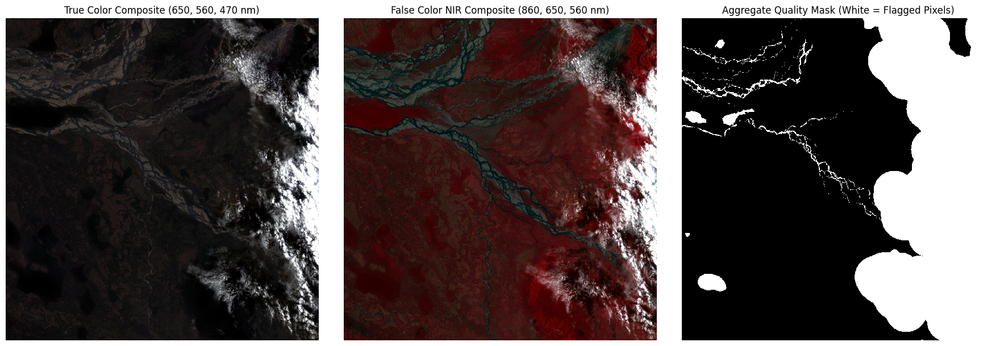

In [48]:
r_b, g_b, b_b = band_idx(650), band_idx(560), band_idx(470)
nir_b = band_idx(860)

true_color = stretch_rgb(cube[:, :, [r_b, g_b, b_b]])
false_color = stretch_rgb(cube[:, :, [nir_b, r_b, g_b]])

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(true_color)
axes[0].set_title("True Color Composite (650, 560, 470 nm)")
axes[1].imshow(false_color)
axes[1].set_title("False Color NIR Composite (860, 650, 560 nm)")
axes[2].imshow(quality_bad_mask, cmap="gray")
axes[2].set_title("Aggregate Quality Mask (White = Flagged Pixels)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Single-Pixel Spectral Extraction with Spatial Crosshairs

### Build an interactive 3-D view of selected spectral slices

This cell downsamples the image grid for a lighter interactive display and stacks seven selected wavelength images (470, 560, 650, 860, 1650, 2200, and 2330 nm) as horizontal surfaces along the 3-D wavelength axis. Each surface is independently scaled for visual contrast. A vertical marker identifies the centre pixel across the selected wavelength levels.

**Expected output:** a Plotly 3-D hyperspectral-cube view that can be rotated and inspected interactively. The spatial axes represent image columns and rows, while the vertical axis represents wavelength in nanometres. The view uses a downsampled grid for rendering, so it is intended for visual exploration rather than quantitative pixel measurement.

In [49]:
import numpy as np
import plotly.graph_objects as go

# Downsample spatial grid for fluid 60 FPS 3D rendering
step = max(1, max(rows, cols) // 180)
sub_cube = cube[::step, ::step, :]
sub_rows, sub_cols, _ = sub_cube.shape

# Select diagnostic bands to stack along the Z-axis (Wavelength)
diag_wls = [470, 560, 650, 860, 1650, 2200, 2330]
diag_b_indices = [band_idx(w) for w in diag_wls]

# Pick target pixel coordinate
target_r_sub = (rows // 2) // step
target_c_sub = (cols // 2) // step

x_grid = np.arange(sub_cols)
y_grid = np.arange(sub_rows)

fig_cube = go.Figure()

# 1. Stack 2D Spatial Wavelength Slices in 3D space
for w_val, b_idx in zip(diag_wls, diag_b_indices):
    slice_data = sub_cube[:, :, b_idx]
    norm_slice = np.clip(slice_data / np.nanpercentile(slice_data, 98), 0, 1)
    
    fig_cube.add_trace(go.Surface(
        x=x_grid,
        y=y_grid,
        z=np.full((sub_rows, sub_cols), w_val),
        surfacecolor=norm_slice,
        colorscale='Viridis',
        showscale=False,
        opacity=0.82,
        name=f"Slice {w_val} nm",
        hoverinfo='skip'
    ))

# 2. Add 3D Spectral Drill-Down Pin (Yellow Crosshair Vector through Z-axis)
target_spectrum_sub = sub_cube[target_r_sub, target_c_sub, diag_b_indices]
fig_cube.add_trace(go.Scatter3d(
    x=[target_c_sub] * len(diag_wls),
    y=[target_r_sub] * len(diag_wls),
    z=diag_wls,
    mode='lines+markers',
    line=dict(color='yellow', width=7),
    marker=dict(size=6, color='crimson', symbol='diamond'),
    name=f"Spectral Core (Row {target_r_sub * step}, Col {target_c_sub * step})"
))

# 3. Layout and 3D Camera Controls
fig_cube.update_layout(
    title=dict(
        text=f"<b>Interactive 3D Hyperspectral Data Cube</b><br><sup>Spatial (X, Y) vs. Spectral Wavelength (Z-axis in nm)</sup>",
        x=0.5
    ),
    scene=dict(
        xaxis=dict(title="Spatial Column (X)", showgrid=True),
        yaxis=dict(title="Spatial Row (Y)", showgrid=True),
        zaxis=dict(title="Wavelength (nm)", range=[350, 2550], showgrid=True),
        aspectratio=dict(x=1.0, y=1.0, z=1.3),
        camera=dict(
            eye=dict(x=1.6, y=-1.6, z=1.2)
        )
    ),
    width=950,
    height=750,
    margin=dict(l=10, r=10, t=60, b=10)
)

fig_cube.show()

### Create a click-to-inspect map and reflectance-spectrum viewer

This cell packages a display-resolution true-colour image and a smaller, quantised version of the reflectance cube into an HTML5/JavaScript widget. The widget places the map beside a spectrum canvas. Clicking or dragging on the map updates the selected location and redraws its reflectance spectrum, with the corresponding map position indicated by crosshairs.

To keep the browser payload manageable, the spectral cube is spatially downsampled and reflectance values are encoded as 8-bit integers. Consequently, the displayed spectrum is an approximate, quantised spectrum from the nearest cell in the reduced spectral buffer, not an exact full-resolution pixel readout. Use the full-resolution arrays for numerical analysis.

**Expected output:** an interactive map-and-spectrum panel rendered inside the notebook. This cell depends on the previously created `cube`, `wl`, and `true_color` variables.


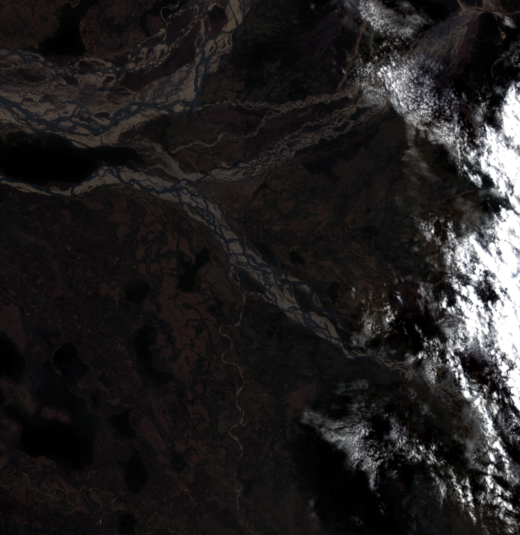

In [50]:
import base64
import io
import json
import numpy as np
from PIL import Image
from IPython.display import HTML, display

# -------------------------------------------------------------------------
# 1. Prepare High-Res Display Image & Memory-Efficient Spectral Buffer
# -------------------------------------------------------------------------
# Sizing for the large display canvas (520px)
disp_map_w = 520
disp_map_h = int(disp_map_w * rows / cols)

# High-quality True Color PNG (sharp, vivid, ~350 KB)
rgb_pil = Image.fromarray((np.clip(true_color, 0, 1) * 255).astype(np.uint8))
rgb_pil = rgb_pil.resize((disp_map_w, disp_map_h), Image.Resampling.BILINEAR)
img_buf = io.BytesIO()
rgb_pil.save(img_buf, format="PNG")
img_b64 = base64.b64encode(img_buf.getvalue()).decode("utf-8")

# Downsample spatial grid for the spectral buffer (~160x160 cells)
# Total payload stays under 8 MB, well below Kaggle's 33 MB output limit
spec_h = 160
spec_w = int(spec_h * cols / rows)

row_indices = np.linspace(0, rows - 1, spec_h).astype(int)
col_indices = np.linspace(0, cols - 1, spec_w).astype(int)
sub_cube = cube[np.ix_(row_indices, col_indices, np.arange(n_bands))]

# Quantize reflectance (0.0 to max_refl_scale) into 8-bit unsigned integers (0-255)
max_scale = float(np.nanpercentile(sub_cube[sub_cube > 0], 99.5))
max_scale = max(0.65, max_scale)
quantized_cube = np.clip((sub_cube / max_scale) * 255, 0, 255).astype(np.uint8)

cube_b64 = base64.b64encode(quantized_cube.tobytes()).decode("utf-8")
wl_json = json.dumps([round(float(w), 1) for w in wl])

# -------------------------------------------------------------------------
# 2. Interactive Click & Drag HTML5 Application
# -------------------------------------------------------------------------
html_code = f"""
<div style="font-family: Arial, sans-serif; background: #161719; color: #e6e6e6; padding: 18px; border-radius: 10px; width: 98%; max-width: 1400px; box-sizing: border-box; user-select: none;">
  
  <div style="display: flex; gap: 20px; justify-content: space-between; align-items: flex-start; flex-wrap: nowrap;">
    
    <!-- LEFT PANEL: Large RGB Map Canvas -->
    <div style="flex-shrink: 0;">
      <div id="coordLabel" style="font-size: 14px; font-weight: bold; margin-bottom: 8px; color: #ffd700;">
        Target: Click or drag on map to inspect spectra
      </div>
      <canvas id="mapCanvas" width="{disp_map_w}" height="{disp_map_h}" 
              style="border: 2px solid #4a4d52; cursor: crosshair; display: block; border-radius: 5px; box-shadow: 0 4px 10px rgba(0,0,0,0.6);"></canvas>
    </div>
    
    <!-- RIGHT PANEL: Large Reflectance Spectrum Canvas -->
    <div style="flex-grow: 1; min-width: 540px;">
      <div id="specTitle" style="font-size: 14px; font-weight: bold; margin-bottom: 8px; color: #38b6ff;">
        Live Surface Reflectance Spectrum
      </div>
      <canvas id="specCanvas" width="700" height="{disp_map_h}" 
              style="background: #0f1012; border: 2px solid #4a4d52; border-radius: 5px; display: block; width: 100%; box-shadow: 0 4px 10px rgba(0,0,0,0.6);"></canvas>
    </div>

  </div>
</div>

<script>
(function() {{
  const mapW = {disp_map_w};
  const mapH = {disp_map_h};
  const specW = {spec_w};
  const specH = {spec_h};
  const nBands = {n_bands};
  const origRows = {rows};
  const origCols = {cols};
  const maxScale = {max_scale};
  const wavelengths = {wl_json};

  // Decode 8-bit quantized spectral cube
  const rawBinary = atob("{cube_b64}");
  const buffer = new ArrayBuffer(rawBinary.length);
  const bytes = new Uint8Array(buffer);
  for (let i = 0; i < rawBinary.length; i++) {{
    bytes[i] = rawBinary.charCodeAt(i);
  }}

  const mapCanvas = document.getElementById('mapCanvas');
  const mapCtx = mapCanvas.getContext('2d');
  const specCanvas = document.getElementById('specCanvas');
  const specCtx = specCanvas.getContext('2d');
  const coordLabel = document.getElementById('coordLabel');
  const specTitle = document.getElementById('specTitle');

  const baseImg = new Image();
  baseImg.src = "data:image/png;base64,{img_b64}";

  let curMapX = Math.floor(mapW / 2);
  let curMapY = Math.floor(mapH / 2);
  let isDragging = false;

  baseImg.onload = function() {{
    drawAll(curMapX, curMapY);
  }};

  function drawMap(px, py) {{
    mapCtx.drawImage(baseImg, 0, 0, mapW, mapH);

    // Yellow Dashed Crosshairs
    mapCtx.strokeStyle = 'yellow';
    mapCtx.lineWidth = 1.4;
    mapCtx.setLineDash([4, 4]);

    mapCtx.beginPath();
    mapCtx.moveTo(0, py + 0.5);
    mapCtx.lineTo(mapW, py + 0.5);
    mapCtx.moveTo(px + 0.5, 0);
    mapCtx.lineTo(px + 0.5, mapH);
    mapCtx.stroke();
    mapCtx.setLineDash([]);

    // Small, clearly visible center dot
    mapCtx.fillStyle = 'yellow';
    mapCtx.beginPath();
    mapCtx.arc(px, py, 2.5, 0, 2 * Math.PI);
    mapCtx.fill();
    mapCtx.strokeStyle = 'black';
    mapCtx.lineWidth = 0.8;
    mapCtx.stroke();
  }}

  function drawSpectrum(px, py) {{
    const sW = specCanvas.width;
    const sH = specCanvas.height;
    specCtx.clearRect(0, 0, sW, sH);

    const padL = 60, padR = 25, padT = 35, padB = 45;
    const plotW = sW - padL - padR;
    const plotH = sH - padT - padB;

    // Grid lines & Y-axis labels
    specCtx.strokeStyle = '#22252a';
    specCtx.lineWidth = 1.0;
    const numYDivs = 6;
    for (let r = 0; r <= numYDivs; r++) {{
      const y = padT + (plotH * r) / numYDivs;
      specCtx.beginPath();
      specCtx.moveTo(padL, y);
      specCtx.lineTo(sW - padR, y);
      specCtx.stroke();

      specCtx.fillStyle = '#8e9297';
      specCtx.font = '11px Arial';
      const val = ((numYDivs - r) * (maxScale / numYDivs)).toFixed(2);
      specCtx.fillText(val, 20, y + 4);
    }}

    const wMin = wavelengths[0];
    const wMax = wavelengths[wavelengths.length - 1];

    // Wavelength X-axis ticks
    const tickWls = [500, 750, 1000, 1250, 1500, 1750, 2000, 2250, 2450];
    for (let tw of tickWls) {{
      const x = padL + ((tw - wMin) / (wMax - wMin)) * plotW;
      specCtx.beginPath();
      specCtx.moveTo(x, padT);
      specCtx.lineTo(x, sH - padB);
      specCtx.stroke();
      specCtx.fillText(tw + " nm", x - 20, sH - padB + 18);
    }}

    // Map mouse position to downsampled spectral grid index
    const sCol = Math.min(specW - 1, Math.max(0, Math.floor((px / mapW) * specW)));
    const sRow = Math.min(specH - 1, Math.max(0, Math.floor((py / mapH) * specH)));
    const offset = (sRow * specW + sCol) * nBands;

    // Plot Blue Reflectance Curve
    specCtx.strokeStyle = '#0077ff';
    specCtx.lineWidth = 2.4;
    specCtx.lineJoin = 'round';
    specCtx.lineCap = 'round';
    specCtx.beginPath();

    let isDrawing = false;
    for (let b = 0; b < nBands; b++) {{
      const wlVal = wavelengths[b];
      const rVal = (bytes[offset + b] / 255.0) * maxScale;

      // Disconnect curve across atmospheric water vapor gaps
      if ((wlVal > 1335 && wlVal < 1455) || (wlVal > 1780 && wlVal < 1980)) {{
        isDrawing = false;
        continue;
      }}

      const x = padL + ((wlVal - wMin) / (wMax - wMin)) * plotW;
      const y = padT + (1.0 - Math.min(rVal / maxScale, 1.0)) * plotH;

      if (!isDrawing) {{
        specCtx.moveTo(x, y);
        isDrawing = true;
      }} else {{
        specCtx.lineTo(x, y);
      }}
    }}
    specCtx.stroke();

    // Axis titles
    specCtx.fillStyle = '#b0b3b8';
    specCtx.font = '12px Arial';
    specCtx.fillText("Reflectance", 12, padT - 14);
    specCtx.fillText("Wavelength (nm)", padL + plotW / 2 - 45, sH - 10);
  }}

  function drawAll(px, py) {{
    drawMap(px, py);
    drawSpectrum(px, py);
    const rOrig = Math.min(origRows - 1, Math.floor((py / mapH) * origRows));
    const cOrig = Math.min(origCols - 1, Math.floor((px / mapW) * origCols));
    coordLabel.innerText = "Target Pixel: Row " + rOrig + ", Column " + cOrig + " (Active Inspection)";
    specTitle.innerText = "Surface Reflectance [Row " + rOrig + ", Col " + cOrig + "]";
  }}

  function updateFromEvent(e) {{
    const rect = mapCanvas.getBoundingClientRect();
    curMapX = Math.max(0, Math.min(mapW - 1, Math.floor(e.clientX - rect.left)));
    curMapY = Math.max(0, Math.min(mapH - 1, Math.floor(e.clientY - rect.top)));
    drawAll(curMapX, curMapY);
  }}

  // Mouse click and drag listeners
  mapCanvas.addEventListener('mousedown', function(e) {{
    isDragging = true;
    updateFromEvent(e);
  }});

  window.addEventListener('mousemove', function(e) {{
    if (isDragging) {{
      const rect = mapCanvas.getBoundingClientRect();
      const x = Math.max(0, Math.min(mapW - 1, Math.floor(e.clientX - rect.left)));
      const y = Math.max(0, Math.min(mapH - 1, Math.floor(e.clientY - rect.top)));
      drawAll(x, y);
    }}
  }});

  window.addEventListener('mouseup', function() {{
    isDragging = false;
  }});

  // Touch support for tablet / touchscreens
  mapCanvas.addEventListener('touchstart', function(e) {{
    if (e.touches.length === 1) {{
      isDragging = true;
      const rect = mapCanvas.getBoundingClientRect();
      const x = Math.max(0, Math.min(mapW - 1, Math.floor(e.touches[0].clientX - rect.left)));
      const y = Math.max(0, Math.min(mapH - 1, Math.floor(e.touches[0].clientY - rect.top)));
      drawAll(x, y);
      e.preventDefault();
    }}
  }}, {{ passive: false }});

  mapCanvas.addEventListener('touchmove', function(e) {{
    if (isDragging && e.touches.length === 1) {{
      const rect = mapCanvas.getBoundingClientRect();
      const x = Math.max(0, Math.min(mapW - 1, Math.floor(e.touches[0].clientX - rect.left)));
      const y = Math.max(0, Math.min(mapH - 1, Math.floor(e.touches[0].clientY - rect.top)));
      drawAll(x, y);
      e.preventDefault();
    }}
  }}, {{ passive: false }});

  mapCanvas.addEventListener('touchend', function() {{
    isDragging = false;
  }});
}})();
</script>
"""

display(HTML(html_code))

## 6. Sub-Scene Crop & Feature Matrix Construction
Extracts a representative 128x128 sub-scene crop and reshapes it into a 2-D feature matrix `X` of shape `(pixels, bands)` for efficient machine learning.

### Extract a spatial crop and construct the pixel-by-band matrix

This cell extracts a square sub-scene using the configured starting row, starting column, and crop size. It extracts the corresponding validity mask, then reshapes the crop from a three-dimensional image cube into a two-dimensional matrix `X`, where each row is a pixel spectrum and each column is a wavelength band.

Invalid or masked pixels are retained in the matrix shape but their values are replaced band by band using the valid-pixel column medians. This keeps the spatial crop rectangular for later reshaping and visualisation; it does not make those imputed spectra genuine observations. The final plot previews the crop as a stretched true-colour composite.

**Check before proceeding:** make sure the selected crop lies within the scene bounds and contains enough valid pixels. Downstream PCA and clustering cells use `X` as the crop-level feature matrix.

Crop Tensor Shape: (128, 128, 255)
Feature Table X:   (16384, 255) (16,384 pixels x 255 bands)


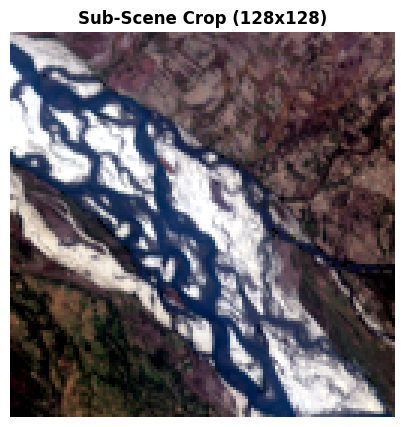

In [51]:
# Define crop coordinates
row0, col0, crop_size = 444, 444, 128

crop_cube = cube[row0:row0 + crop_size, col0:col0 + crop_size, :]
crop_valid = valid_pixel_mask[row0:row0 + crop_size, col0:col0 + crop_size]

# Reshape into tabular matrix: (16,384 pixels x n_bands)
X = crop_cube.reshape(-1, n_bands).copy()
valid_flat = crop_valid.ravel()

# Robustly impute any invalid/masked pixels using column medians
if not np.all(valid_flat):
    col_medians = np.nanmedian(np.where(X[valid_flat] > 0, X[valid_flat], np.nan), axis=0)
    col_medians = np.nan_to_num(col_medians, nan=0.0)
    for col_idx in range(n_bands):
        bad_idx = (~valid_flat) | (~np.isfinite(X[:, col_idx]))
        X[bad_idx, col_idx] = col_medians[col_idx]

print(f"Crop Tensor Shape: {crop_cube.shape}")
print(f"Feature Table X:   {X.shape} ({X.shape[0]:,} pixels x {n_bands} bands)")

# Preview crop RGB composite
r_b, g_b, b_b = band_idx(650), band_idx(560), band_idx(470)
plt.figure(figsize=(5, 5))
plt.imshow(stretch_rgb(crop_cube[:, :, [r_b, g_b, b_b]]))
plt.title(f"Sub-Scene Crop ({crop_size}x{crop_size})", fontweight="bold")
plt.axis("off")
plt.show()

## 7. Spectral Scatter, Random Profiles & Band Redundancy Analysis

### Explore band relationships, pixel spectra, and spectral redundancy

This cell samples valid image locations and creates three complementary diagnostics. The first set of plots compares reflectance values at selected wavelength pairs to show how pixels are distributed between bands. The second plots spectra from a random selection of valid pixels, allowing variation in overall brightness and spectral shape to be inspected. The final panel calculates and displays the band-to-band correlation matrix from the sampled pixels.

**How to interpret the outputs:** strong positive correlations between bands indicate similar spatial variation and possible spectral redundancy; weaker or negative relationships may highlight different surface responses. Individual spectral curves can reveal broad absorption and reflectance features, but atmospheric gaps and noisy bands should be considered when interpreting them. The plots are based on samples, not every pixel in the scene.

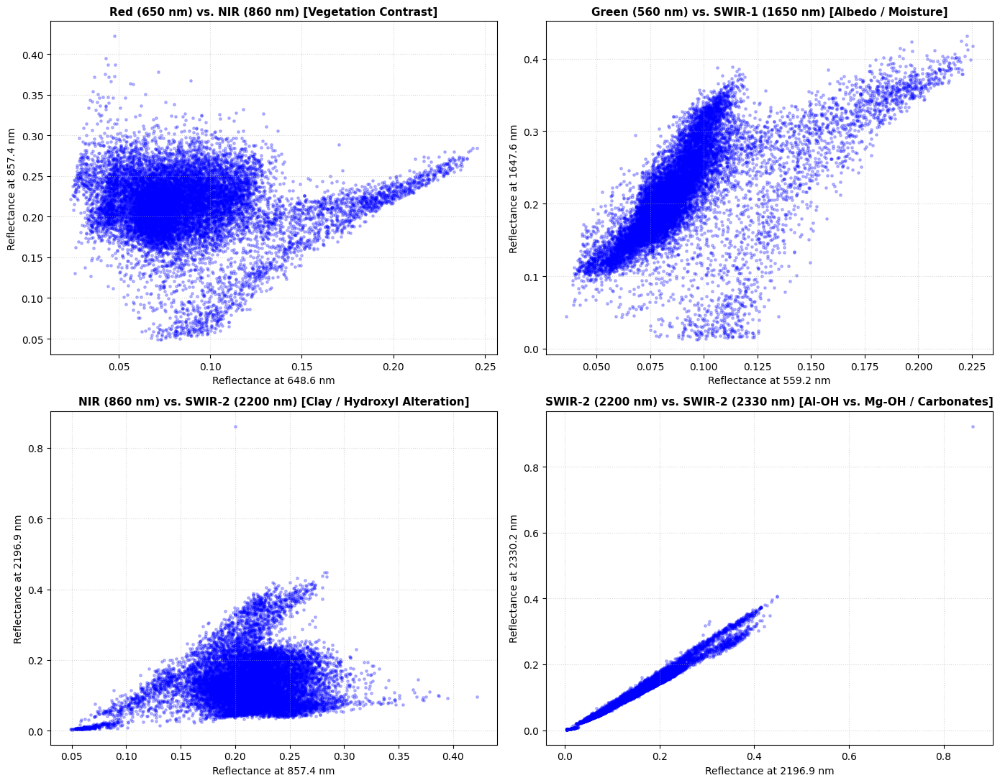

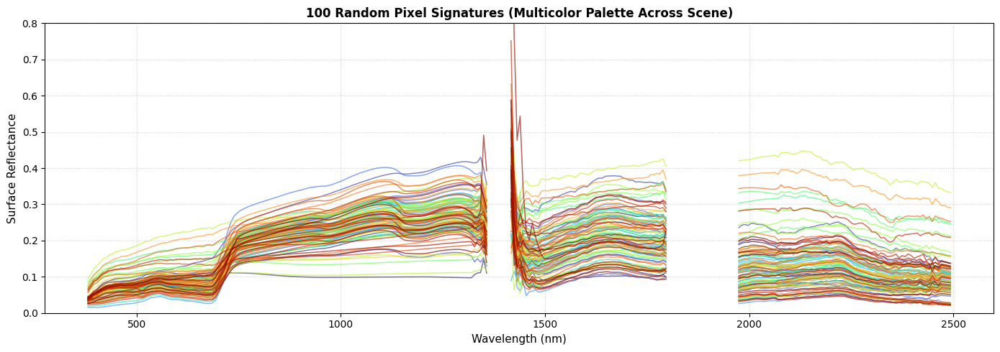

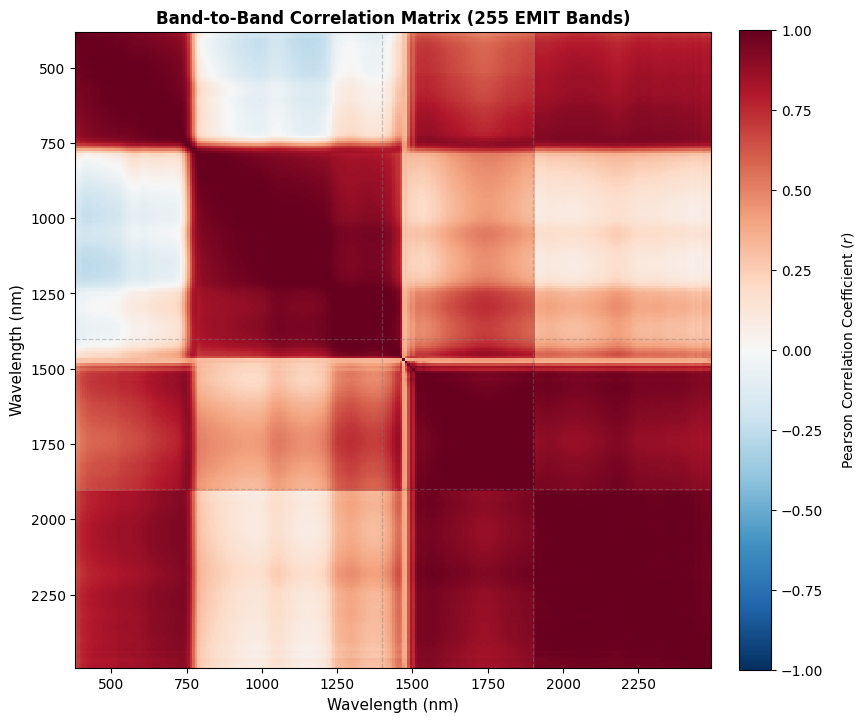

In [52]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# 0. Resolve Helper Functions & Coordinates
# -------------------------------------------------------------------------
b_func = band_idx if 'band_idx' in globals() else band

# Ensure valid coordinates are defined from the quality mask
if 'valid_r' not in globals() or 'valid_c' not in globals():
    if 'valid_pixel_mask' in globals() and valid_pixel_mask.shape == cube.shape[:2]:
        valid_r, valid_c = np.where(valid_pixel_mask)
    else:
        valid_r, valid_c = np.where(np.all(cube > 0, axis=-1))

# Subsample valid pixels for scatter & correlation analysis
np.random.seed(42)
sample_size = min(15000, len(valid_r))
sample_idx = np.random.choice(len(valid_r), size=sample_size, replace=False)
sub_r, sub_c = valid_r[sample_idx], valid_c[sample_idx]
sample_pixels = cube[sub_r, sub_c, :]  # Shape: (15000, n_bands)

# -------------------------------------------------------------------------
# 1. Diagnostic 2D Spectral Scatter Plots (Blue)
# -------------------------------------------------------------------------
pairs = [
    (650, 860, "Red (650 nm) vs. NIR (860 nm) [Vegetation Contrast]"),
    (560, 1650, "Green (560 nm) vs. SWIR-1 (1650 nm) [Albedo / Moisture]"),
    (860, 2200, "NIR (860 nm) vs. SWIR-2 (2200 nm) [Clay / Hydroxyl Alteration]"),
    (2200, 2330, "SWIR-2 (2200 nm) vs. SWIR-2 (2330 nm) [Al-OH vs. Mg-OH / Carbonates]")
]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.ravel()

for i, (w1, w2, title) in enumerate(pairs):
    b1, b2 = b_func(w1), b_func(w2)
    val1 = sample_pixels[:, b1]
    val2 = sample_pixels[:, b2]
    
    axes[i].scatter(val1, val2, color='blue', alpha=0.25, s=6, rasterized=True)
    axes[i].set_xlabel(f"Reflectance at {wl[b1]:.1f} nm", fontsize=10)
    axes[i].set_ylabel(f"Reflectance at {wl[b2]:.1f} nm", fontsize=10)
    axes[i].set_title(title, fontsize=11, fontweight="bold")
    axes[i].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 2. 100 Random Pixel Signatures in Vibrant Colors
# -------------------------------------------------------------------------
n_signatures = 100
sig_sample_idx = np.random.choice(len(valid_r), size=min(n_signatures, len(valid_r)), replace=False)
palette = plt.cm.turbo(np.linspace(0, 1, len(sig_sample_idx)))

fig, ax = plt.subplots(figsize=(14, 5))
for i, idx in enumerate(sig_sample_idx):
    r_pix, c_pix = valid_r[idx], valid_c[idx]
    sig = cube[r_pix, c_pix, :]
    if 'plot_spectrum_gap_aware' in globals():
        plot_spectrum_gap_aware(ax, wl, sig, color=palette[i], alpha=0.65, linewidth=1.1)
    else:
        ax.plot(wl, sig, color=palette[i], alpha=0.65, linewidth=1.1)

ax.set_xlabel("Wavelength (nm)", fontsize=11)
ax.set_ylabel("Surface Reflectance", fontsize=11)
ax.set_title("100 Random Pixel Signatures (Multicolor Palette Across Scene)", fontweight="bold", fontsize=12)
ax.set_ylim(0, 0.8)
ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 3. Band-to-Band Correlation Matrix Plot
# -------------------------------------------------------------------------
# Transposing sample_pixels gives shape (n_bands, n_pixels) for band-to-band correlation
corr_matrix = np.corrcoef(sample_pixels.T)

fig, ax = plt.subplots(figsize=(8.5, 7.5))
im_corr = ax.imshow(
    corr_matrix, 
    cmap="RdBu_r", 
    vmin=-1.0, 
    vmax=1.0, 
    extent=[wl[0], wl[-1], wl[-1], wl[0]]
)

ax.set_title(f"Band-to-Band Correlation Matrix ({len(wl)} EMIT Bands)", fontweight="bold", fontsize=12)
ax.set_xlabel("Wavelength (nm)", fontsize=11)
ax.set_ylabel("Wavelength (nm)", fontsize=11)

# Highlight atmospheric water-vapor absorption gaps as reference lines
for gap_center in [1400, 1900]:
    ax.axvline(gap_center, color='gray', linestyle='--', alpha=0.4, linewidth=0.9)
    ax.axhline(gap_center, color='gray', linestyle='--', alpha=0.4, linewidth=0.9)

cbar = fig.colorbar(im_corr, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Pearson Correlation Coefficient ($r$)", rotation=90, labelpad=12, fontsize=10)

plt.tight_layout()
plt.show()

## 8. Interactive 3-D Scatter Visualization

### Inspect a 3-D reflectance feature space using visible and NIR bands

This cell randomly samples up to 3,000 pixel spectra from `X` and plots each pixel as a point in a three-dimensional feature space. The axes use reflectance at the bands nearest to 470 nm (blue), 650 nm (red), and 860 nm (near infrared).

**How to read the plot:** each point represents one sampled pixel, and point groupings indicate pixels with similar reflectance combinations across these three wavelengths. The axes are spectral measurements, not geographic coordinates. Clusters or gaps in this view are exploratory patterns and should not be treated as validated material classes.

In [53]:

# Sample pixel indices
rng = np.random.default_rng(seed=42)
sub_ids = rng.choice(len(X), min(3000, len(X)), replace=False)

# Get the closest band indices for blue, red, and NIR wavelengths
b_470 = band_idx(470)
b_650 = band_idx(650)
b_860 = band_idx(860)

fig_3d = px.scatter_3d(
    x=X[sub_ids, b_470],
    y=X[sub_ids, b_650],
    z=X[sub_ids, b_860],
    labels={
        "x": f"Reflectance at {wl[b_470]:.1f} nm (Blue)",
        "y": f"Reflectance at {wl[b_650]:.1f} nm (Red)",
        "z": f"Reflectance at {wl[b_860]:.1f} nm (NIR)"
    },
    title="3D Spectral Scatter (470 nm vs. 650 nm vs. 860 nm)",
    opacity=0.6
)
fig_3d.update_traces(marker=dict(size=3))
fig_3d.show()

### Explore a 3-D feature space using three randomly selected bands

This cell ensures that a valid-pixel feature matrix `X` exists, samples up to 3,000 spectra, and randomly selects three distinct wavelength bands. It then plots the sampled pixels in a Plotly 3-D scatter plot using reflectance at those three bands as the axes.

The selected wavelengths are printed so that the axes can be interpreted. Because the band selection is random and no fixed seed is set for that selection, a new execution may show a different three-band combination. Use this as an exploratory view of spectral-space structure; it is not a repeatable diagnostic until the selected bands are recorded.

In [54]:

# Ensure X is defined from valid pixels if not already present
if 'X' not in globals():
    X = cube[valid_pixel_mask]

# Subsample pixels for smooth 3D rendering
sub_ids = np.random.choice(len(X), size=min(3000, len(X)), replace=False)

# Randomly pick 3 distinct band indices without a fixed seed
b_x, b_y, b_z = np.random.choice(len(wl), size=3, replace=False)

# Corresponding wavelengths in nm
wl_x, wl_y, wl_z = wl[b_x], wl[b_y], wl[b_z]
print(f"Selected Bands -> X: {wl_x:.1f} nm (Band {b_x}), Y: {wl_y:.1f} nm (Band {b_y}), Z: {wl_z:.1f} nm (Band {b_z})")

# Generate 3D scatter plot
fig_3d = px.scatter_3d(
    x=X[sub_ids, b_x],
    y=X[sub_ids, b_y],
    z=X[sub_ids, b_z],
    labels={
        "x": f"Reflectance @ {wl_x:.1f} nm",
        "y": f"Reflectance @ {wl_y:.1f} nm",
        "z": f"Reflectance @ {wl_z:.1f} nm"
    },
    title=f"3D Spectral Scatter: {wl_x:.1f} nm vs. {wl_y:.1f} nm vs. {wl_z:.1f} nm",
    opacity=0.65
)

fig_3d.update_traces(marker=dict(size=3))
fig_3d.show()

Selected Bands -> X: 1454.0 nm (Band 137), Y: 1260.3 nm (Band 118), Z: 1707.1 nm (Band 171)


## 9. Principal Component Analysis (PCA) & Scree Analysis
Decomposes the high-dimensional cube into orthogonal variance components and identifies the scree elbow.

### Quantify spectral dimensionality with PCA scree diagnostics

This cell extracts valid surface spectra from the full cube and randomly selects up to 35,000 pixels for a manageable PCA evaluation. PCA is fitted with up to 20 components. The outputs include a linear scree plot, a log-scale scree plot, cumulative explained variance with candidate component counts, and a table reporting cumulative and marginal variance for the candidate counts (3, 4, 5, 10, 15, and 20).

**Purpose:** assess how rapidly variance is concentrated in the leading components and identify a reasonable dimensionality for later feature-space analysis. The variance percentages describe this sampled dataset and the reflectance representation used here; they do not by themselves establish how many mineral classes are present.

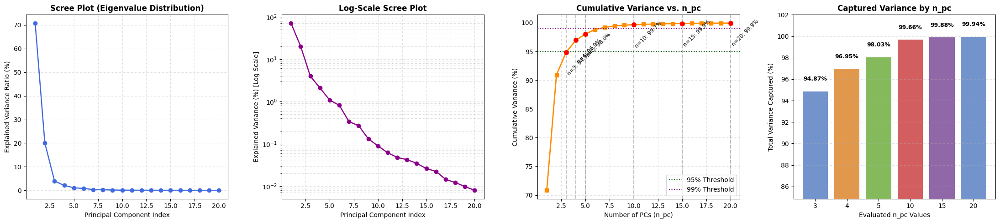

,Candidate n_pc,Cumulative Variance (%),Marginal PC Variance (%)
0,3,94.866791,3.960613
1,4,96.949776,2.082988
2,5,98.029747,1.079978
3,10,99.664070,0.088987
4,15,99.876320,0.026021
5,20,99.943039,0.007974


In [55]:
# Flatten valid pixels and subsample for PCA & manifold analysis
X_valid = cube[valid_pixel_mask]
np.random.seed(42)
pca_sample_size = min(35000, len(X_valid))
pca_subset_idx = np.random.choice(len(X_valid), size=pca_sample_size, replace=False)
X_pca_sub = X_valid[pca_subset_idx]

# Fit full PCA to assess scree and candidate n_pc values
max_eval_pc = 20
pca_full = PCA(n_components=max_eval_pc, random_state=42)
pca_full.fit(X_pca_sub)

# Candidate n_pc values
candidate_npcs = [3, 4, 5, 10, 15, 20]
exp_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(exp_var)

fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# 1. Individual Scree Plot (Linear Scale)
axes[0].plot(range(1, max_eval_pc + 1), exp_var * 100, marker='o', color='royalblue', linewidth=1.8)
axes[0].set_xlabel("Principal Component Index")
axes[0].set_ylabel("Explained Variance Ratio (%)")
axes[0].set_title("Scree Plot (Eigenvalue Distribution)", fontweight="bold")
axes[0].grid(True, linestyle=":", alpha=0.6)

# 2. Individual Scree Plot (Log Scale)
axes[1].plot(range(1, max_eval_pc + 1), exp_var * 100, marker='o', color='darkmagenta', linewidth=1.8)
axes[1].set_yscale('log')
axes[1].set_xlabel("Principal Component Index")
axes[1].set_ylabel("Explained Variance (%) [Log Scale]")
axes[1].set_title("Log-Scale Scree Plot", fontweight="bold")
axes[1].grid(True, which="both", linestyle=":", alpha=0.6)

# 3. Cumulative Variance with Candidate Thresholds
axes[2].plot(range(1, max_eval_pc + 1), cum_var * 100, marker='s', color='darkorange', linewidth=2.0)
for npc in candidate_npcs:
    val = cum_var[npc - 1] * 100
    axes[2].axvline(npc, color='gray', linestyle='--', alpha=0.5)
    axes[2].scatter(npc, val, color='red', s=45, zorder=5)
    axes[2].annotate(f"n={npc}: {val:.1f}%", (npc, val - 4), fontsize=8.5, rotation=45)

axes[2].axhline(95, color='darkgreen', linestyle=':', label='95% Threshold')
axes[2].axhline(99, color='purple', linestyle=':', label='99% Threshold')
axes[2].set_xlabel("Number of PCs (n_pc)")
axes[2].set_ylabel("Cumulative Variance (%)")
axes[2].set_title("Cumulative Variance vs. n_pc", fontweight="bold")
axes[2].legend(loc="lower right")
axes[2].grid(True, linestyle=":", alpha=0.6)

# 4. Bar Chart Comparison of Evaluated n_pc Values
bar_vals = [cum_var[n - 1] * 100 for n in candidate_npcs]
bars = axes[3].bar([str(n) for n in candidate_npcs], bar_vals, color=['#7293CB', '#E1974C', '#84BA5B', '#D35E60', '#9067A7'])
axes[3].set_xlabel("Evaluated n_pc Values")
axes[3].set_ylabel("Total Variance Captured (%)")
axes[3].set_ylim(min(bar_vals) - 10, 102)
axes[3].set_title("Captured Variance by n_pc", fontweight="bold")
for bar, val in zip(bars, bar_vals):
    axes[3].text(bar.get_x() + bar.get_width()/2, val + 1.0, f"{val:.2f}%", ha='center', fontsize=9, fontweight='bold')
axes[3].grid(True, axis='y', linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

# Display summary table
df_pca = pd.DataFrame({
    "Candidate n_pc": candidate_npcs,
    "Cumulative Variance (%)": [cum_var[n-1]*100 for n in candidate_npcs],
    "Marginal PC Variance (%)": [exp_var[n-1]*100 for n in candidate_npcs]
})
display(df_pca)

### Review and manually mark the PCA scree-plot elbow

This cell takes the explained-variance ratios from the preceding PCA evaluation and marks a manually selected cutoff, currently `elbow_pc = 3`. It displays the selected component on both linear and logarithmic scree plots and reports the variance explained by that component and the cumulative variance retained through the selected cutoff.

**User decision:** inspect the scree curve and change `elbow_pc` to the component where the marginal variance contribution begins to diminish substantially. The cutoff is an analyst-selected parameter, not an automatically optimised result. Keep the retained component count consistent with the settings used by later PCA and t-SNE steps.

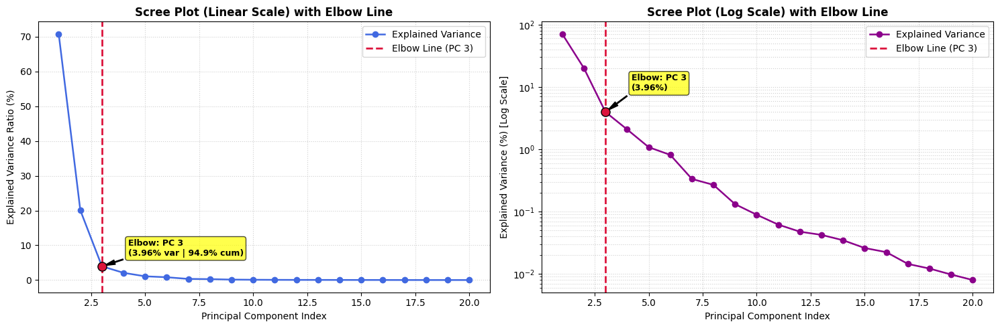

Selected Elbow Cutoff: PC 1 through PC 3
Variance explained by PC 3: 3.96%
Total cumulative variance retained: 94.87%


In [56]:
# ==============================================================================
# MANUALLY CONFIGURE YOUR ELBOW VALUE HERE:
# ==============================================================================
elbow_pc = 3  # <-- Change this integer (e.g., 3, 4, 5, 6, etc.) to set the elbow cutoff

# Retrieve explained variance from previous cell if available
if 'exp_var' not in globals():
    exp_var = pca_full.explained_variance_ratio_

pc_indices = np.arange(1, len(exp_var) + 1)
elbow_val = exp_var[elbow_pc - 1] * 100
cum_elbow_val = np.sum(exp_var[:elbow_pc]) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# ------------------------------------------------------------------------------
# 1. Linear Scale Scree Plot with Elbow Line
# ------------------------------------------------------------------------------
axes[0].plot(pc_indices, exp_var * 100, marker='o', color='royalblue', linewidth=1.8, label="Explained Variance")
axes[0].axvline(elbow_pc, color='crimson', linestyle='--', linewidth=2.0, label=f'Elbow Line (PC {elbow_pc})')
axes[0].scatter(elbow_pc, elbow_val, color='crimson', s=90, zorder=5, edgecolor='black')

axes[0].annotate(
    f'Elbow: PC {elbow_pc}\n({elbow_val:.2f}% var | {cum_elbow_val:.1f}% cum)',
    xy=(elbow_pc, elbow_val),
    xytext=(elbow_pc + 1.2, elbow_val + (3.0 if elbow_val < 30 else -8.0)),
    arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=5),
    fontsize=9, fontweight='bold',
    bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.7, ec="black")
)

axes[0].set_xlabel("Principal Component Index")
axes[0].set_ylabel("Explained Variance Ratio (%)")
axes[0].set_title("Scree Plot (Linear Scale) with Elbow Line", fontweight="bold")
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(loc="upper right")

# ------------------------------------------------------------------------------
# 2. Log Scale Scree Plot with Elbow Line
# ------------------------------------------------------------------------------
axes[1].plot(pc_indices, exp_var * 100, marker='o', color='darkmagenta', linewidth=1.8, label="Explained Variance")
axes[1].set_yscale('log')
axes[1].axvline(elbow_pc, color='crimson', linestyle='--', linewidth=2.0, label=f'Elbow Line (PC {elbow_pc})')
axes[1].scatter(elbow_pc, elbow_val, color='crimson', s=90, zorder=5, edgecolor='black')

axes[1].annotate(
    f'Elbow: PC {elbow_pc}\n({elbow_val:.2f}%)',
    xy=(elbow_pc, elbow_val),
    xytext=(elbow_pc + 1.2, elbow_val * 2.2),
    arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=5),
    fontsize=9, fontweight='bold',
    bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.7, ec="black")
)

axes[1].set_xlabel("Principal Component Index")
axes[1].set_ylabel("Explained Variance (%) [Log Scale]")
axes[1].set_title("Scree Plot (Log Scale) with Elbow Line", fontweight="bold")
axes[1].grid(True, which="both", linestyle=":", alpha=0.6)
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

print(f"Selected Elbow Cutoff: PC 1 through PC {elbow_pc}")
print(f"Variance explained by PC {elbow_pc}: {elbow_val:.2f}%")
print(f"Total cumulative variance retained: {cum_elbow_val:.2f}%")

## 10. PC Projections, Spatial Score Maps & Albedo Loading Analysis

### Project crop spectra into PCA space and inspect PC1 brightness effects

This cell resolves or creates a PCA model, checks that the crop feature matrix `X` has the expected number of pixels, and fits the PCA model if it has not already been fitted. It transforms the crop spectra into PCA scores stored in `P` and calculates the correlation between PC1 scores and mean reflectance per pixel.

The three panels show the PC1-versus-PC2 score distribution, the spatial map of PC1 scores, and the PC1/PC2 spectral loading curves. A strong correlation between PC1 and mean reflectance suggests that the first component is substantially associated with broad-band brightness or albedo variation.

**Interpretation:** PCA scores describe variation in the input spectra, and loadings show how wavelengths contribute to each component. A PC should not be assigned a mineral identity from its loading curve alone.

Correlation between PC1 and Mean Pixel Reflectance: 0.9901
-> Strong correlation: PC1 is dominated by broad-band surface brightness / albedo.


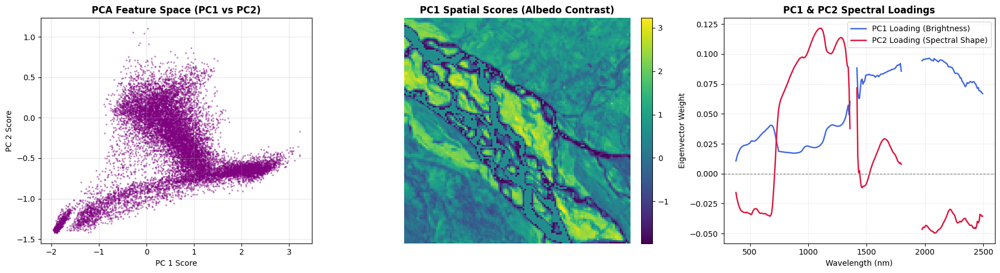

In [57]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Ensure PCA model is loaded from Cell 9
if 'pca' not in globals():
    if 'pca_full' in globals():
        pca = pca_full
    elif 'pca_opt' in globals():
        pca = pca_opt
    else:
        from sklearn.decomposition import PCA
        pca = PCA(n_components=10, random_state=42)

# 2. Ensure crop_size and spatial patch X are defined and shape-aligned
if 'crop_size' not in globals():
    crop_size = min(300, rows, cols)

# Ensure X has exactly crop_size * crop_size pixels for 2D spatial reshaping
expected_len = crop_size * crop_size
if 'X' not in globals() or getattr(X, 'shape', (0,))[0] != expected_len:
    r_center = target_row if 'target_row' in globals() else rows // 2
    c_center = target_col if 'target_col' in globals() else cols // 2
    r_start = max(0, min(rows - crop_size, r_center - crop_size // 2))
    c_start = max(0, min(cols - crop_size, c_center - crop_size // 2))
    
    crop = cube[r_start:r_start + crop_size, c_start:c_start + crop_size, :]
    X = crop.reshape(-1, n_bands)

# Ensure PCA model is fitted
if not hasattr(pca, 'components_'):
    pca.fit(X)

# 3. Compute P (PCA projection scores)
P = pca.transform(X)

# Correlation between PC1 and broadband pixel reflectance
pc1_corr = np.corrcoef(P[:, 0], X.mean(axis=1))[0, 1]
print(f"Correlation between PC1 and Mean Pixel Reflectance: {pc1_corr:.4f}")
if abs(pc1_corr) > 0.85:
    print("-> Strong correlation: PC1 is dominated by broad-band surface brightness / albedo.")

# 4. Generate Diagnostic Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. PC1 vs PC2 Scatter Plot
axes[0].scatter(P[:, 0], P[:, 1], s=2, alpha=0.35, color="purple")
axes[0].set_xlabel("PC 1 Score")
axes[0].set_ylabel("PC 2 Score")
axes[0].set_title("PCA Feature Space (PC1 vs PC2)", fontweight="bold")
axes[0].grid(alpha=0.3)

# 2. PC1 Spatial Map
im_pc1 = axes[1].imshow(P[:, 0].reshape(crop_size, crop_size), cmap="viridis")
axes[1].set_title("PC1 Spatial Scores (Albedo Contrast)", fontweight="bold")
axes[1].axis("off")
fig.colorbar(im_pc1, ax=axes[1], fraction=0.046, pad=0.04)

# 3. Spectral Loadings for PC1 and PC2 with fixed, consistent colors
plot_spectrum_gap_aware(
    axes[2], wl, pca.components_[0], 
    color="royalblue", 
    label="PC1 Loading (Brightness)", 
    lw=1.8
)
plot_spectrum_gap_aware(
    axes[2], wl, pca.components_[1], 
    color="crimson", 
    label="PC2 Loading (Spectral Shape)", 
    lw=1.8
)

axes[2].axhline(0, color="gray", ls="--", lw=0.9)
axes[2].set_xlabel("Wavelength (nm)")
axes[2].set_ylabel("Eigenvector Weight")
axes[2].set_title("PC1 & PC2 Spectral Loadings", fontweight="bold")
axes[2].grid(True, linestyle=":", alpha=0.5)
axes[2].legend(loc="upper right")

plt.tight_layout()
plt.show()

### Examine PCA loading profiles and rank influential wavelengths

This cell selects the active PCA model and its matching wavelength array, then examines the first two component loading vectors. The three-panel diagnostic shows (1) loading versus wavelength, with selected diagnostic wavelength positions marked; (2) PC1-versus-PC2 loading values, where each point represents a wavelength; and (3) a wavelength-importance curve formed from the absolute loadings weighted by explained-variance ratios.

A table ranks the ten wavelengths with the highest calculated importance and reports their PC1 and PC2 loading values. These wavelengths can guide closer spectral inspection, but PCA importance is a statistical measure of variance contribution, not direct evidence of a particular mineral absorption or mineral abundance. Consider the instrument's valid-band selection and atmospheric regions when interpreting the ranking.

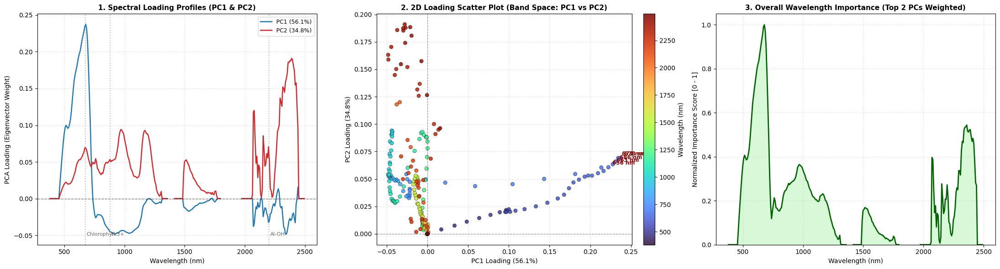

=== TOP 10 DIAGNOSTIC WAVELENGTHS DETECTED BY PCA ===


,Rank,Wavelength (nm),Normalized Importance,PC1 Loading,PC2 Loading
0,1,678.41,1.0000,0.2372,0.0691
1,2,670.95,0.9903,0.2344,0.0692
2,3,685.86,0.9720,0.2313,0.0660
3,4,663.49,0.9539,0.2278,0.0634
4,5,656.04,0.9285,0.2224,0.0607
5,6,648.58,0.8998,0.2164,0.0573
6,7,693.32,0.8969,0.2137,0.0605
7,8,641.13,0.8708,0.2096,0.0553
8,9,633.67,0.8394,0.2022,0.0531
9,10,626.22,0.8230,0.1975,0.0531


In [58]:
# -------------------------------------------------------------------------
# 1. Resolve Active PCA Model & Wavelengths
# -------------------------------------------------------------------------
pca_obj = pca_cr if 'pca_cr' in globals() else (pca_eval if 'pca_eval' in globals() else pca)
wl_arr = granule_wl if 'granule_wl' in globals() else wl

# PCA components matrix shape: (n_components, n_bands)
loadings = pca_obj.components_
evr = pca_obj.explained_variance_ratio_
n_pcs_to_show = min(2, loadings.shape[0])

# -------------------------------------------------------------------------
# 2. Plot Tri-Panel Diagnostic Loading Analysis
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# --- PANEL 1: 1D Spectral Loading Curves (Wavelength vs Loading) ---
palette_pcs = ['#1f77b4', '#d62728', '#2ca02c', '#ff7f0e']
for i in range(n_pcs_to_show):
    # Mask atmospheric water gaps for cleaner curves
    if 'plot_spectrum_gap_aware' in globals():
        plot_spectrum_gap_aware(
            axes[0], wl_arr, loadings[i], 
            color=palette_pcs[i], lw=1.8, 
            label=f"PC{i+1} ({evr[i]*100:.1f}%)"
        )
    else:
        axes[0].plot(wl_arr, loadings[i], color=palette_pcs[i], lw=1.8, label=f"PC{i+1} ({evr[i]*100:.1f}%)")

axes[0].axhline(0, color='black', ls='--', alpha=0.5, lw=1)
axes[0].set_title("1. Spectral Loading Profiles (PC1 & PC2)", fontweight="bold", fontsize=11)
axes[0].set_xlabel("Wavelength (nm)")
axes[0].set_ylabel("PCA Loading (Eigenvector Weight)")
axes[0].grid(True, ls=":", alpha=0.5)
axes[0].legend(loc="upper right", fontsize=9)

# Highlight known physical diagnostic positions
for w_pos, w_txt in [(675, "Chlorophyll"), (880, "Fe3+"), (2200, "Al-OH")]:
    axes[0].axvline(w_pos, color='gray', ls=':', alpha=0.5)
    axes[0].text(w_pos + 10, axes[0].get_ylim()[0]*0.8, w_txt, fontsize=8, color='dimgray')

# --- PANEL 2: 2D Loading Scatter Plot (PC1 vs PC2) ---
pc1_w = loadings[0]
pc2_w = loadings[1]

# Scatter where each point is one spectral wavelength
sc = axes[1].scatter(
    pc1_w, pc2_w, 
    c=wl_arr, cmap="turbo", 
    s=35, edgecolor='black', lw=0.4, alpha=0.85
)
axes[1].axhline(0, color='black', ls='--', alpha=0.4, lw=0.9)
axes[1].axvline(0, color='black', ls='--', alpha=0.4, lw=0.9)
axes[1].set_title("2. 2D Loading Scatter Plot (Band Space: PC1 vs PC2)", fontweight="bold", fontsize=11)
axes[1].set_xlabel(f"PC1 Loading ({evr[0]*100:.1f}%)")
axes[1].set_ylabel(f"PC2 Loading ({evr[1]*100:.1f}%)")
axes[1].grid(True, ls=":", alpha=0.5)

cbar = fig.colorbar(sc, ax=axes[1], fraction=0.046, pad=0.04)
cbar.set_label("Wavelength (nm)", rotation=90)

# Annotate diagnostic bands with the highest leverage / distance from origin
dist_from_origin = np.sqrt(pc1_w**2 + pc2_w**2)
top_leverage_idx = np.argsort(dist_from_origin)[-5:]  # Top 5 most influential bands
for idx in top_leverage_idx:
    axes[1].annotate(
        f"{wl_arr[idx]:.0f} nm", 
        (pc1_w[idx], pc2_w[idx]),
        textcoords="offset points", xytext=(6, 4), 
        fontsize=8.5, fontweight="bold", color="darkred"
    )

# --- PANEL 3: Overall Wavelength Importance Spectrum ---
# Weighted sum of absolute loadings by explained variance ratio
total_importance = np.zeros(len(wl_arr))
for i in range(n_pcs_to_show):
    total_importance += evr[i] * np.abs(loadings[i])

# Normalize 0 to 1
total_importance /= np.nanmax(total_importance)

if 'plot_spectrum_gap_aware' in globals():
    plot_spectrum_gap_aware(axes[2], wl_arr, total_importance, color='darkgreen', lw=2.0)
else:
    axes[2].plot(wl_arr, total_importance, color='darkgreen', lw=2.0)

axes[2].fill_between(wl_arr, 0, total_importance, color='lightgreen', alpha=0.35)
axes[2].set_title(f"3. Overall Wavelength Importance (Top {n_pcs_to_show} PCs Weighted)", fontweight="bold", fontsize=11)
axes[2].set_xlabel("Wavelength (nm)")
axes[2].set_ylabel("Normalized Importance Score [0 - 1]")
axes[2].set_ylim(0, 1.05)
axes[2].grid(True, ls=":", alpha=0.5)

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 3. Print Top 10 Ranked Wavelengths
# -------------------------------------------------------------------------
top10_idx = np.argsort(total_importance)[::-1][:10]
df_top_wl = pd.DataFrame({
    "Rank": range(1, 11),
    "Wavelength (nm)": [f"{wl_arr[i]:.2f}" for i in top10_idx],
    "Normalized Importance": [f"{total_importance[i]:.4f}" for i in top10_idx],
    "PC1 Loading": [f"{loadings[0, i]:.4f}" for i in top10_idx],
    "PC2 Loading": [f"{loadings[1, i]:.4f}" for i in top10_idx]
})

print("=== TOP 10 DIAGNOSTIC WAVELENGTHS DETECTED BY PCA ===")
display(df_top_wl)

## 11. Standardized t-SNE Dimensionality Reduction
Standardizes the retained principal components so PC1 variance does not swamp diagnostic spectral features, and computes a fast 2-D non-linear manifold embedding.

### Prepare clean spectra and compare t-SNE perplexity settings

This cell extracts a spatial crop and aligns it with the available quality mask. It removes spectra that are masked, non-finite, negative, very dark, or nearly spectrally flat, then deduplicates spectra after rounding reflectance values. PCA reduces the retained spectra to three components, and `StandardScaler` standardises those PC scores before t-SNE.

A reproducible sample of up to 2,500 unique spectra is embedded three times using perplexities 15, 30, and 50. The resulting panels allow the sensitivity of the two-dimensional manifold layout to the perplexity setting to be compared. t-SNE preserves aspects of local neighbourhood structure but can distort global distances and cluster sizes; use these plots to assess visual stability, not as a physical map or a standalone proof of class separation.

Loaded existing 'P_raw' projection: 16,384 samples x 4 PCs
Evaluating t-SNE on 10,000 raw PCA samples...
  -> Computing t-SNE embedding (perplexity = 30)...
  -> Computing t-SNE embedding (perplexity = 50)...
  -> Computing t-SNE embedding (perplexity = 150)...


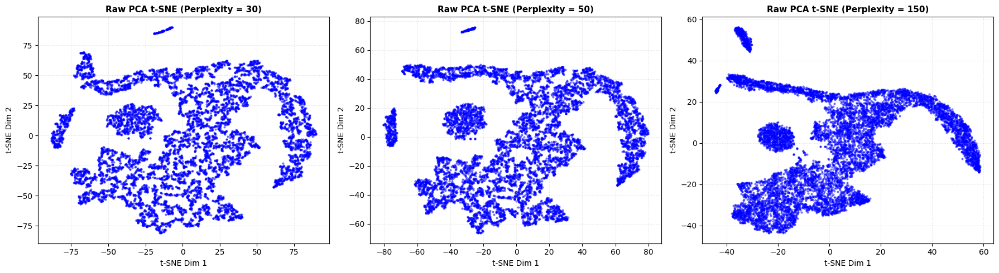

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# -------------------------------------------------------------------------
# 1. Resolve Raw PCA Scores from Previous Cells (No Refitting / No StandardScaler)
# -------------------------------------------------------------------------
# Determine number of components (typically 4 PCs capture >99.7% variance in raw data)
n_pcs = elbow if 'elbow' in globals() else (n_pcs_used if 'n_pcs_used' in globals() else 4)

if 'P_raw' in globals():
    # Use precomputed raw PCA projection from Cell 10/11
    pc_features = P_raw[:, :n_pcs].copy()
    print(f"Loaded existing 'P_raw' projection: {pc_features.shape[0]:,} samples x {n_pcs} PCs")
elif 'pca_raw' in globals() and 'X' in globals():
    # Transform raw crop table X using the existing fitted pca_raw
    pc_features = pca_raw.transform(X)[:, :n_pcs].copy()
    print(f"Transformed 'X' with existing 'pca_raw': {pc_features.shape[0]:,} samples x {n_pcs} PCs")
else:
    from sklearn.decomposition import PCA
    # Fallback: Fit directly on raw crop array without StandardScaler
    pca_raw_fallback = PCA(n_components=n_pcs, random_state=42)
    pc_features = pca_raw_fallback.fit_transform(X)[:, :n_pcs]
    print(f"Fit fallback PCA on raw data: {pc_features.shape[0]:,} samples x {n_pcs} PCs")

# -------------------------------------------------------------------------
# 2. Density-Preserving Subsampling & Anti-Duplicate Micro-Jitter
# -------------------------------------------------------------------------
# Increase sample size to 8,000-10,000 so t-SNE has sufficient manifold density
np.random.seed(42)
sample_size = min(10000, len(pc_features))
sample_idx = np.random.choice(len(pc_features), size=sample_size, replace=False)
tsne_input = pc_features[sample_idx].copy()

# Add microscopic jitter to duplicate points to avoid t-SNE ring artifacts
# without deleting points (which breaks cluster density distributions)
_, u_idx = np.unique(np.round(tsne_input, decimals=5), axis=0, return_index=True)
dup_mask = np.ones(len(tsne_input), dtype=bool)
dup_mask[u_idx] = False
if np.any(dup_mask):
    tsne_input[dup_mask] += np.random.normal(0, 1e-5, size=tsne_input[dup_mask].shape)

print(f"Evaluating t-SNE on {len(tsne_input):,} raw PCA samples...")

# -------------------------------------------------------------------------
# 3. Evaluate t-SNE Manifold across Perplexities (15, 30, 50)
# -------------------------------------------------------------------------
perplexities = [30, 50, 150]
fig, axes = plt.subplots(1, len(perplexities), figsize=(18, 5))

for i, perp in enumerate(perplexities):
    print(f"  -> Computing t-SNE embedding (perplexity = {perp})...")
    tsne_model = TSNE(
        n_components=2,
        perplexity=perp,
        early_exaggeration=12,
        learning_rate='auto',
        init='pca',
        random_state=0,
        max_iter=1000
    )
    embedding = tsne_model.fit_transform(tsne_input)
    
    axes[i].scatter(embedding[:, 0], embedding[:, 1], color='blue', s=4, alpha=0.45, rasterized=True)
    axes[i].set_title(f"Raw PCA t-SNE (Perplexity = {perp})", fontweight="bold", fontsize=11)
    axes[i].set_xlabel("t-SNE Dim 1")
    axes[i].set_ylabel("t-SNE Dim 2")
    axes[i].grid(True, linestyle=":", alpha=0.4)

plt.tight_layout()
plt.show()

## 12. K-Means Cluster Validation & Model Fitting
Evaluates cluster quality metrics (Silhouette, Davies-Bouldin, Calinski-Harabasz) across candidate $K$ values and fits K-Means in standardized PCA space.

### Validate candidate cluster counts using t-SNE and spectral-angle separation

If a t-SNE embedding `T` is not already available, this cell builds one from the selected PCA scores, adding a very small jitter to duplicate feature vectors as a safeguard against zero-distance artefacts. It then fits K-Means for candidate cluster counts from 2 through 7. For each candidate, it calculates cluster mean spectra and pairwise Spectral Angle Mapper (SAM) distances over the selected valid wavelength region.

The cell presents a SAM separation table, a plot of the minimum inter-cluster spectral angle against the candidate cluster count, and mean-spectrum diagnostics for selected values of K (3, 4, and 5). Use these results together with the scree analysis, spatial coherence, and geological context when choosing K. A larger minimum angle or a visually separated t-SNE plot alone does not validate a mineral classification.

=== Scientific Spectral Separability Across k = 2 to 7 ===


,Clusters (k),Min Inter-Class Angle (deg),Mean Inter-Class Angle (deg),Status
0,2,13.86,13.86,Physically Distinct
1,3,9.38,12.93,Physically Distinct
2,4,1.61,11.21,Over-Segmented (Duplicate)
3,5,3.85,13.08,Physically Distinct
4,6,2.57,12.63,Over-Segmented (Duplicate)
5,7,1.66,12.11,Over-Segmented (Duplicate)


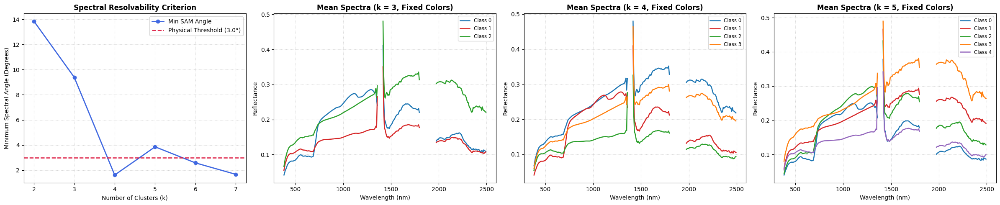

In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Ensure t-SNE manifold T is available
if 'T' not in globals() or T is None:
    n_pcs_used = elbow if 'elbow' in globals() else 4
    P_input = P[:, :n_pcs_used].copy()
    
    # Anti-duplicate jitter guard to prevent t-SNE bullseye
    _, unique_idx = np.unique(np.round(P_input, decimals=5), axis=0, return_index=True)
    dup_mask = np.ones(len(P_input), dtype=bool)
    dup_mask[unique_idx] = False
    if np.any(dup_mask):
        np.random.seed(42)
        P_input[dup_mask] += np.random.normal(0, 1e-5, size=P_input[dup_mask].shape)
        
    tsne_model = TSNE(
        n_components=2, 
        perplexity=30, 
        early_exaggeration=12,
        learning_rate="auto", 
        max_iter=1000,
        init="pca", 
        random_state=0
    )
    T = tsne_model.fit_transform(P_input)
    
# 1. Evaluate spectral angle separability across k = 2 to 7
k_range = list(range(2, 8))
min_sam_deg = []
mean_sam_deg = []
all_mean_spectra = {}

# Use only valid surface wavelengths (masking atmospheric noise windows)
good_spec_mask = (wl >= 450) & (wl <= 2450) & ~((wl >= 1340) & (wl <= 1450)) & ~((wl >= 1790) & (wl <= 1970))

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=0)
    lbls = km.fit_predict(T)
    
    # Calculate mean spectrum per cluster
    means = np.array([X[lbls == c].mean(axis=0) for c in range(k)])
    all_mean_spectra[k] = means
    
    # Compute pairwise SAM matrix (in degrees)
    angles = []
    for i in range(k):
        for j in range(i + 1, k):
            u = means[i, good_spec_mask]
            v = means[j, good_spec_mask]
            cos_sim = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v) + 1e-10)
            angle = np.degrees(np.arccos(np.clip(cos_sim, -1.0, 1.0)))
            angles.append(angle)
            
    min_sam_deg.append(np.min(angles))
    mean_sam_deg.append(np.mean(angles))

# 2. Display Spectral Angle Separability Table
df_sam = pd.DataFrame({
    "Clusters (k)": k_range,
    "Min Inter-Class Angle (deg)": min_sam_deg,
    "Mean Inter-Class Angle (deg)": mean_sam_deg,
    "Status": [
        "Physically Distinct" if ang >= 3.0 else "Over-Segmented (Duplicate)"
        for ang in min_sam_deg
    ]
})
print("=== Scientific Spectral Separability Across k = 2 to 7 ===")
display(df_sam.round(2))

# 3. Diagnostic Plots (1 Row, 4 Subplots)
fig, axes = plt.subplots(1, 4, figsize=(24, 5))

DISTINCT_COLORS = ['#1f77b4', '#d62728', '#2ca02c', '#ff7f0e', '#9467bd', '#17becf', '#bcbd22']

# Plot 1: Minimum Inter-Cluster Angle vs. Threshold
axes[0].plot(k_range, min_sam_deg, marker='o', color='royalblue', linewidth=2, label="Min SAM Angle")
axes[0].axhline(3.0, color='crimson', linestyle='--', linewidth=1.8, label="Physical Threshold (3.0°)")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Minimum Spectral Angle (Degrees)")
axes[0].set_title("Spectral Resolvability Criterion", fontweight="bold")
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(loc="upper right")

# Plot 2: Color-Synchronized Mean Spectra for k = 3
for c in range(3):
    plot_spectrum_gap_aware(
        axes[1], wl, all_mean_spectra[3][c], 
        color=DISTINCT_COLORS[c], 
        linewidth=1.8, 
        label=f"Class {c}"
    )
axes[1].set_xlabel("Wavelength (nm)")
axes[1].set_ylabel("Reflectance")
axes[1].set_title("Mean Spectra (k = 3, Fixed Colors)", fontweight="bold")
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(loc="upper right", fontsize=8.5)

# Plot 3: Color-Synchronized Mean Spectra for k = 4
for c in range(4):
    plot_spectrum_gap_aware(
        axes[2], wl, all_mean_spectra[4][c], 
        color=DISTINCT_COLORS[c], 
        linewidth=1.8, 
        label=f"Class {c}"
    )
axes[2].set_xlabel("Wavelength (nm)")
axes[2].set_ylabel("Reflectance")
axes[2].set_title("Mean Spectra (k = 4, Fixed Colors)", fontweight="bold")
axes[2].grid(True, linestyle=":", alpha=0.6)
axes[2].legend(loc="upper right", fontsize=8.5)

# Plot 4: Color-Synchronized Mean Spectra for k = 5
for c in range(5):
    plot_spectrum_gap_aware(
        axes[3], wl, all_mean_spectra[5][c], 
        color=DISTINCT_COLORS[c], 
        linewidth=1.8, 
        label=f"Class {c}"
    )
axes[3].set_xlabel("Wavelength (nm)")
axes[3].set_ylabel("Reflectance")
axes[3].set_title("Mean Spectra (k = 5, Fixed Colors)", fontweight="bold")
axes[3].grid(True, linestyle=":", alpha=0.6)
axes[3].legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()

### Fit the selected K-Means model and create a crop classification map

Set `k_final` to the chosen number of clusters after reviewing the preceding diagnostics. This cell fits K-Means directly to the two-dimensional t-SNE coordinates `T`, assigns a cluster label to each sample, and displays the embedding coloured by cluster alongside the corresponding two-dimensional crop classification map. It also stores the labels and fitted model in variables used by subsequent attribution steps.

The map shows unsupervised spectral classes within the analysed crop. Cluster numbers are arbitrary identifiers and do not represent an inherent mineral ordering. The result depends on the selected K, the t-SNE embedding, the crop, and the input preprocessing.

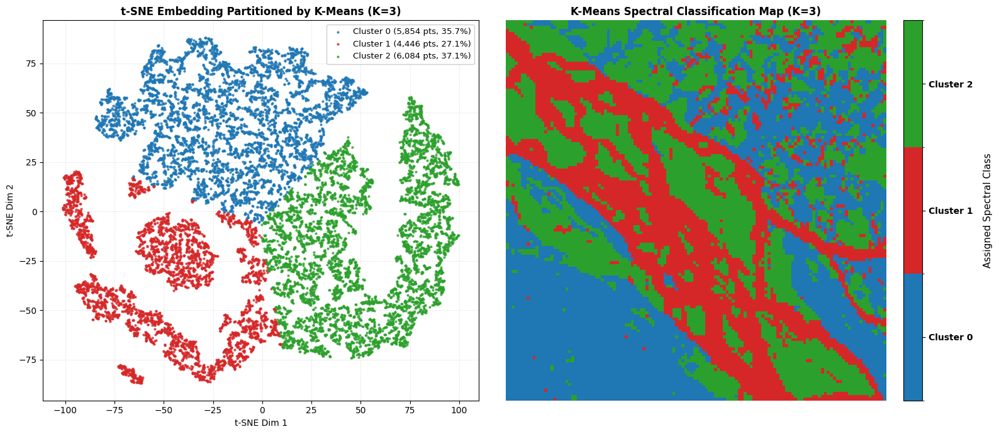

Classification map and 3 clusters ready for spectral attribution.


In [61]:
# ==============================================================================
# MANUALLY SELECT YOUR CHOSEN k VALUE:
# ==============================================================================
k_final = 3  # <-- Set your chosen k (2, 3, 4, 5, 6, 7) based on Cell 12A scores

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from sklearn.cluster import KMeans

# 1. Fit K-Means directly on t-SNE coordinates T (original notebook architecture)
km_final = KMeans(n_clusters=k_final, n_init=10, random_state=0)
labels = km_final.fit_predict(T)

# 2. Distinct, non-overlapping color palette
DISTINCT_COLORS = [
    '#1f77b4',  # 0: Blue
    '#d62728',  # 1: Red
    '#2ca02c',  # 2: Green
    '#ff7f0e',  # 3: Orange
    '#9467bd',  # 4: Purple
    '#17becf',  # 5: Cyan
    '#bcbd22',  # 6: Olive
]
palette = DISTINCT_COLORS[:k_final]
custom_cmap = ListedColormap(palette)
bounds = np.arange(k_final + 1) - 0.5
norm = BoundaryNorm(bounds, custom_cmap.N)

# 3. Side-by-side Dual Space Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Plot 1: t-SNE Embedding Partitioned by K-Means
for c in range(k_final):
    mask = (labels == c)
    pts_count = np.sum(mask)
    pct = (pts_count / len(labels)) * 100
    axes[0].scatter(
        T[mask, 0], 
        T[mask, 1], 
        color=palette[c], 
        s=4, 
        alpha=0.75, 
        label=f"Cluster {c} ({pts_count:,} pts, {pct:.1f}%)"
    )

axes[0].set_title(f"t-SNE Embedding Partitioned by K-Means (K={k_final})", fontweight="bold", fontsize=12)
axes[0].set_xlabel("t-SNE Dim 1")
axes[0].set_ylabel("t-SNE Dim 2")
axes[0].grid(True, linestyle=":", alpha=0.45)
axes[0].legend(loc="upper right", framealpha=0.95, fontsize=9.5)

# Plot 2: K-Means Spectral Classification Map (using crop_size)
map_2d = labels.reshape(crop_size, crop_size)
im = axes[1].imshow(map_2d, cmap=custom_cmap, norm=norm, interpolation="nearest")
axes[1].set_title(f"K-Means Spectral Classification Map (K={k_final})", fontweight="bold", fontsize=12)
axes[1].axis("off")

# Synchronized colorbar
cbar = fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04, ticks=range(k_final))
cbar.set_ticklabels([f"Cluster {c}" for c in range(k_final)], fontsize=10, fontweight="bold")
cbar.ax.set_ylabel("Assigned Spectral Class", rotation=90, labelpad=12, fontsize=11)

plt.tight_layout()
plt.show()

# 4. Save variables for downstream USGS Library Identification (Cell 14)
cluster_labels_all = labels
X_valid = X
optimal_km = km_final
print(f"Classification map and {k_final} clusters ready for spectral attribution.")

## 13. Sub-Scene Surface Classification Map

### Compare the crop classification map with its true-colour context

This cell resolves the available cluster labels, reshapes them to the crop dimensions, and prepares a true-colour preview using the bands nearest to 650, 560, and 470 nm. It displays the RGB crop beside the discrete K-Means class map with a colourbar identifying the class numbers.

**Purpose:** visually assess where the unsupervised spectral classes occur relative to visible surface patterns. This is a spatial-context check only; the class numbers have not been converted into mineral names in this cell. Compare class boundaries with the original image and consider whether the patterns are spatially coherent.

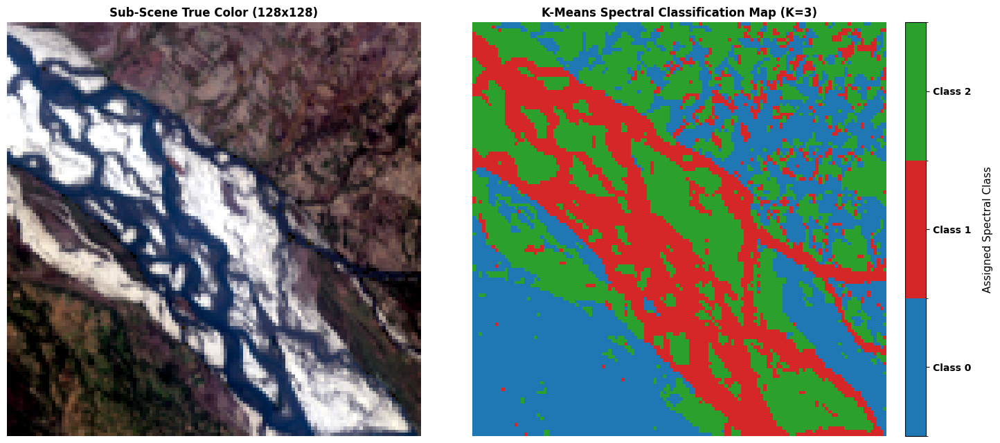

In [62]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

# 1. Resolve cluster labels from Cell 12B
if 'crop_labels' in globals():
    active_labels = crop_labels
elif 'labels' in globals():
    active_labels = labels
elif 'cluster_labels_all' in globals():
    active_labels = cluster_labels_all
else:
    raise NameError("No cluster labels found. Please run Cell 12B first.")

# Ensure crop_size and k_final are set
k_val = k_final if 'k_final' in globals() else len(np.unique(active_labels))
actual_crop_size = crop_size if 'crop_size' in globals() else int(np.sqrt(len(active_labels)))
class_map = active_labels.reshape(actual_crop_size, actual_crop_size)

# 2. Synchronized discrete palette (matching Cell 12B)
DISTINCT_COLORS = [
    '#1f77b4',  # 0: Blue
    '#d62728',  # 1: Red
    '#2ca02c',  # 2: Green
    '#ff7f0e',  # 3: Orange
    '#9467bd',  # 4: Purple
    '#17becf',  # 5: Cyan
    '#bcbd22',  # 6: Olive
]
palette = DISTINCT_COLORS[:k_val]
custom_cmap = ListedColormap(palette)
bounds = np.arange(k_val + 1) - 0.5
norm = BoundaryNorm(bounds, custom_cmap.N)

# 3. Ensure RGB display helper and band indices are available
if 'r_b' not in globals() or 'g_b' not in globals() or 'b_b' not in globals():
    b_func = band if 'band' in globals() else band_idx
    r_b, g_b, b_b = b_func(650), b_func(560), b_func(470)

rgb_disp_fn = stretch_rgb if 'stretch_rgb' in globals() else stretch
rgb_preview = rgb_disp_fn(crop_cube[:, :, [r_b, g_b, b_b]])

# 4. Side-by-Side Comparison Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

# Subplot 1: Original Sub-Scene True Color
axes[0].imshow(rgb_preview)
axes[0].set_title(f"Sub-Scene True Color ({actual_crop_size}x{actual_crop_size})", fontweight="bold", fontsize=12)
axes[0].axis("off")

# Subplot 2: K-Means Spectral Classification Map
im_cls = axes[1].imshow(class_map, cmap=custom_cmap, norm=norm, interpolation="nearest")
axes[1].set_title(f"K-Means Spectral Classification Map (K={k_val})", fontweight="bold", fontsize=12)
axes[1].axis("off")

# Colorbar with exact discrete labels
cbar = fig.colorbar(im_cls, ax=axes[1], fraction=0.046, pad=0.04, ticks=range(k_val))
cbar.set_ticklabels([f"Class {c}" for c in range(k_val)], fontsize=10, fontweight="bold")
cbar.ax.set_ylabel("Assigned Spectral Class", rotation=90, labelpad=12, fontsize=11)

plt.tight_layout()
plt.show()

### Compare raw reflectance with segmented upper-hull continuum removal

This cell builds a more explicit raw-versus-continuum-removed experiment on the crop spectra. It defines a gap-aware plotting helper and an upper-convex-hull continuum-removal procedure, applying the operation separately within three wavelength windows (VNIR, SWIR-1, and SWIR-2) so that large atmospheric absorption gaps are not bridged by a single continuum. It then fits separate PCA models to the raw and continuum-removed spectra and computes corresponding t-SNE embeddings.

The diagnostic figures compare representative spectra, explained-variance/scree behaviour, PCA score distributions, t-SNE manifold geometry, band-to-band correlation matrices, and spectral loading patterns for the two representations. A quantitative summary reports how the leading-PC variance and cumulative variance change after continuum removal.

**Purpose:** test whether continuum removal reduces broad brightness/albedo effects and makes absorption-related spectral variation more prominent. Review the actual plots and metrics rather than assuming that continuum removal is automatically superior; the outcome depends on the spectra, wavelength windows, and preprocessing choices.

Fitting upper convex hulls across spectral transmission windows...
Computing t-SNE for Raw PCA features...
Computing t-SNE for True Continuum-Removed PCA features...


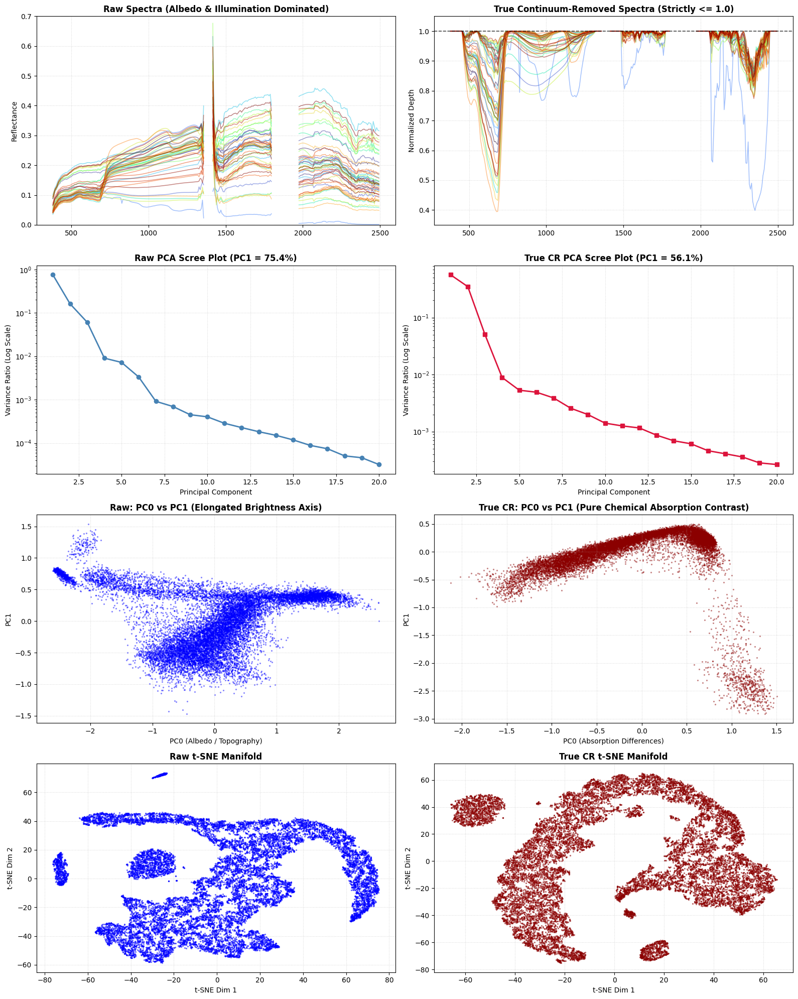

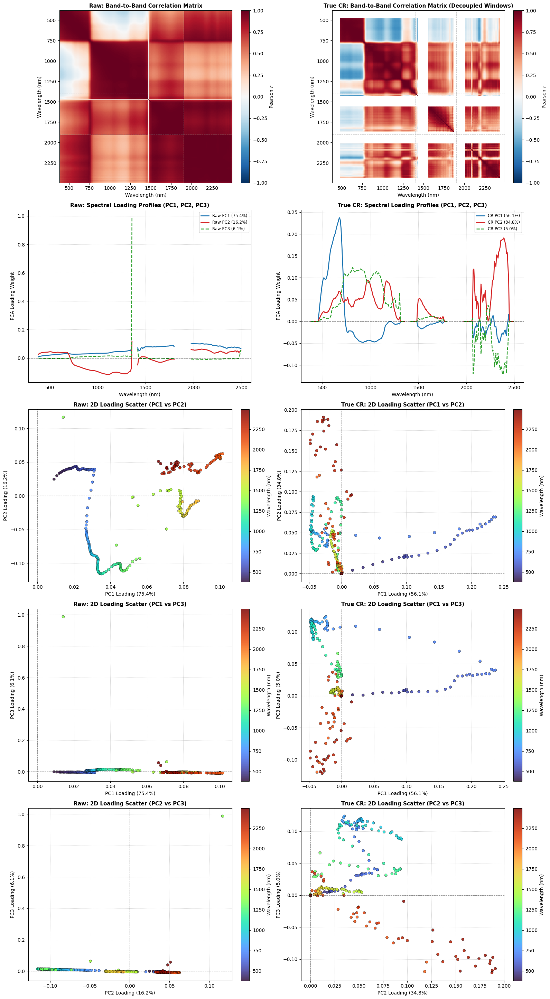


=== Final Quantitative Comparison: Raw vs True CR ===
1. PC1 Variance Explained:
   • Raw Reflectance        : 75.37%
   • True Continuum-Removed : 56.10%
   -> Brightness variance reduction: 19.28%

2. Variance Held in First 4 PCs:
   • Raw Reflectance        : 98.54%
   • True Continuum-Removed : 96.86%


In [65]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# -------------------------------------------------------------------------
# 0. Helper Functions & Safeguards
# -------------------------------------------------------------------------
def safe_plot_spectrum(ax, wavelengths, spectrum, **kwargs):
    if 'plot_spectrum_gap_aware' in globals():
        plot_spectrum_gap_aware(ax, wavelengths, spectrum, **kwargs)
    else:
        w = np.asarray(wavelengths)
        s = np.asarray(spectrum)
        gap_mask = ((w >= 1340) & (w <= 1450)) | ((w >= 1790) & (w <= 1970))
        s_masked = np.ma.masked_where(gap_mask | ~np.isfinite(s) | (s <= 0), s)
        ax.plot(w, s_masked, **kwargs)

# -------------------------------------------------------------------------
# 1. True Upper Convex Hull Continuum Removal (Strictly <= 1.0)
# -------------------------------------------------------------------------
def single_spectrum_convex_hull(w_val, s_val):
    """Computes upper convex hull envelope for a single spectral segment."""
    valid = np.isfinite(s_val) & (s_val > 0)
    if np.sum(valid) < 3:
        return np.maximum(np.nan_to_num(s_val, nan=1e-4), 1e-4)
    
    y_clean = np.interp(w_val, w_val[valid], s_val[valid]) if not np.all(valid) else s_val.copy()
    try:
        pts = np.vstack([w_val, y_clean]).T
        bottom_pts = np.array([[w_val[-1], 0.0], [w_val[0], 0.0]])
        poly = np.vstack([pts, bottom_pts])
        
        hull = ConvexHull(poly)
        upper_vertices = sorted([v for v in hull.vertices if v < len(w_val)])
        
        if 0 not in upper_vertices:
            upper_vertices.insert(0, 0)
        if (len(w_val) - 1) not in upper_vertices:
            upper_vertices.append(len(w_val) - 1)
            
        upper_wl = w_val[upper_vertices]
        upper_refl = y_clean[upper_vertices]
        
        continuum = np.interp(w_val, upper_wl, upper_refl)
        return np.maximum(continuum, 1e-4)
    except Exception:
        p = np.polyfit([w_val[0], w_val[-1]], [y_clean[0], y_clean[-1]], 1)
        return np.maximum(np.polyval(p, w_val), 1e-4)

def apply_true_convex_continuum_removal(X_table, wavelengths):
    """
    Computes true upper convex hull continuum removal across the 3 primary 
    atmospheric transmission windows. Strictly guarantees X_cr <= 1.0.
    """
    X_cr = np.ones_like(X_table, dtype=np.float32)
    
    windows = [
        (wavelengths >= 450) & (wavelengths <= 1320),   # VNIR
        (wavelengths >= 1480) & (wavelengths <= 1780),  # SWIR-1
        (wavelengths >= 2050) & (wavelengths <= 2450)   # SWIR-2
    ]
    
    print("Fitting upper convex hulls across spectral transmission windows...")
    for win in windows:
        sub_wl = wavelengths[win]
        sub_X = X_table[:, win]
        
        cont_matrix = np.empty_like(sub_X)
        for i in range(len(sub_X)):
            cont_matrix[i] = single_spectrum_convex_hull(sub_wl, sub_X[i])
            
        ratio = sub_X / cont_matrix
        X_cr[:, win] = np.clip(np.nan_to_num(ratio, nan=1.0, posinf=1.0, neginf=1.0), 0.0, 1.0)
        
    return np.nan_to_num(X_cr, nan=1.0, posinf=1.0, neginf=1.0)

# Compute True Upper Convex Hull CR
X_cr = apply_true_convex_continuum_removal(X, wl)

# -------------------------------------------------------------------------
# 2. Dual PCA Execution (Raw vs. True CR)
# -------------------------------------------------------------------------
n_pc_eval = 20
pca_raw = PCA(n_components=n_pc_eval).fit(X)
P_raw = pca_raw.transform(X)

pca_cr = PCA(n_components=n_pc_eval).fit(X_cr)
P_cr = pca_cr.transform(X_cr)

n_pcs_used = elbow if 'elbow' in globals() else 4

# -------------------------------------------------------------------------
# 3. Dual t-SNE Execution
# -------------------------------------------------------------------------
def run_tsne_safely(P_in, pcs):
    P_sub = P_in[:, :pcs].copy()
    _, u_idx = np.unique(np.round(P_sub, decimals=5), axis=0, return_index=True)
    dup_mask = np.ones(len(P_sub), dtype=bool)
    dup_mask[u_idx] = False
    if np.any(dup_mask):
        np.random.seed(42)
        P_sub[dup_mask] += np.random.normal(0, 1e-5, size=P_sub[dup_mask].shape)
    
    return TSNE(
        n_components=2, 
        perplexity=100, 
        early_exaggeration=12, 
        learning_rate="auto", 
        max_iter=1000, 
        init="pca", 
        random_state=0
    ).fit_transform(P_sub)

print("Computing t-SNE for Raw PCA features...")
T_raw = run_tsne_safely(P_raw, n_pcs_used)

print("Computing t-SNE for True Continuum-Removed PCA features...")
T_cr = run_tsne_safely(P_cr, n_pcs_used)

# -------------------------------------------------------------------------
# 4. Diagnostic Comparison Plot 1: Spectra, Scree, Latent Space & Manifold
# -------------------------------------------------------------------------
fig1, axes1 = plt.subplots(4, 2, figsize=(16, 20))

np.random.seed(42)
sample_idx = np.random.choice(len(X), size=50, replace=False)
palette = plt.cm.turbo(np.linspace(0, 1, len(sample_idx)))

# Row 1: Spectra
for i, s_idx in enumerate(sample_idx):
    safe_plot_spectrum(axes1[0, 0], wl, X[s_idx], color=palette[i], alpha=0.5, linewidth=1.1)
    safe_plot_spectrum(axes1[0, 1], wl, X_cr[s_idx], color=palette[i], alpha=0.5, linewidth=1.1)

axes1[0, 0].set_title("Raw Spectra (Albedo & Illumination Dominated)", fontweight="bold")
axes1[0, 0].set_ylabel("Reflectance")
axes1[0, 0].set_ylim(0, 0.7)
axes1[0, 0].grid(True, linestyle=":", alpha=0.5)

axes1[0, 1].set_title("True Continuum-Removed Spectra (Strictly <= 1.0)", fontweight="bold")
axes1[0, 1].set_ylabel("Normalized Depth")
axes1[0, 1].set_ylim(0.35, 1.05)
axes1[0, 1].axhline(1.0, color='black', linestyle='--', alpha=0.7, linewidth=1.2)
axes1[0, 1].grid(True, linestyle=":", alpha=0.5)

# Row 2: Scree Plot
axes1[1, 0].plot(range(1, n_pc_eval + 1), pca_raw.explained_variance_ratio_, "o-", color="steelblue", lw=2)
axes1[1, 0].set_yscale("log")
axes1[1, 0].set_title(f"Raw PCA Scree Plot (PC1 = {pca_raw.explained_variance_ratio_[0]:.1%})", fontweight="bold")
axes1[1, 0].set_xlabel("Principal Component")
axes1[1, 0].set_ylabel("Variance Ratio (Log Scale)")
axes1[1, 0].grid(True, linestyle=":", alpha=0.5)

axes1[1, 1].plot(range(1, n_pc_eval + 1), pca_cr.explained_variance_ratio_, "s-", color="crimson", lw=2)
axes1[1, 1].set_yscale("log")
axes1[1, 1].set_title(f"True CR PCA Scree Plot (PC1 = {pca_cr.explained_variance_ratio_[0]:.1%})", fontweight="bold")
axes1[1, 1].set_xlabel("Principal Component")
axes1[1, 1].set_ylabel("Variance Ratio (Log Scale)")
axes1[1, 1].grid(True, linestyle=":", alpha=0.5)

# Row 3: PC0 vs PC1 Projection
axes1[2, 0].scatter(P_raw[:, 0], P_raw[:, 1], color="blue", s=2, alpha=0.35, rasterized=True)
axes1[2, 0].set_title("Raw: PC0 vs PC1 (Elongated Brightness Axis)", fontweight="bold")
axes1[2, 0].set_xlabel("PC0 (Albedo / Topography)")
axes1[2, 0].set_ylabel("PC1")
axes1[2, 0].grid(True, linestyle=":", alpha=0.5)

axes1[2, 1].scatter(P_cr[:, 0], P_cr[:, 1], color="darkred", s=2, alpha=0.35, rasterized=True)
axes1[2, 1].set_title("True CR: PC0 vs PC1 (Pure Chemical Absorption Contrast)", fontweight="bold")
axes1[2, 1].set_xlabel("PC0 (Absorption Differences)")
axes1[2, 1].set_ylabel("PC1")
axes1[2, 1].grid(True, linestyle=":", alpha=0.5)

# Row 4: t-SNE Manifold Geometry
axes1[3, 0].scatter(T_raw[:, 0], T_raw[:, 1], color="blue", s=2, alpha=0.45, rasterized=True)
axes1[3, 0].set_title("Raw t-SNE Manifold", fontweight="bold")
axes1[3, 0].set_xlabel("t-SNE Dim 1")
axes1[3, 0].set_ylabel("t-SNE Dim 2")
axes1[3, 0].grid(True, linestyle=":", alpha=0.5)

axes1[3, 1].scatter(T_cr[:, 0], T_cr[:, 1], color="darkred", s=2, alpha=0.45, rasterized=True)
axes1[3, 1].set_title("True CR t-SNE Manifold", fontweight="bold")
axes1[3, 1].set_xlabel("t-SNE Dim 1")
axes1[3, 1].set_ylabel("t-SNE Dim 2")
axes1[3, 1].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 5. Diagnostic Comparison Plot 2: Correlation, Loadings & Dual 2D Scatter Suite
# -------------------------------------------------------------------------
n_corr_sample = min(15000, len(X))
corr_idx = np.random.choice(len(X), size=n_corr_sample, replace=False)

# Transposing gives (n_bands, n_pixels) for band-to-band correlation
corr_raw = np.corrcoef(np.nan_to_num(X[corr_idx], nan=0.0).T)
corr_cr  = np.corrcoef(np.nan_to_num(X_cr[corr_idx], nan=1.0).T)

# 5 rows x 2 columns: Correlation, Profiles (PC1-3), and 3 Scatter Projections (PC1vPC2, PC1vPC3, PC2vPC3)
fig2, axes2 = plt.subplots(5, 2, figsize=(16, 29))

# --- ROW 1: Band-to-Band Correlation Matrix ---
extent_grid = [wl[0], wl[-1], wl[-1], wl[0]]

im_c_raw = axes2[0, 0].imshow(corr_raw, cmap="RdBu_r", vmin=-1.0, vmax=1.0, extent=extent_grid)
axes2[0, 0].set_title("Raw: Band-to-Band Correlation Matrix", fontweight="bold", fontsize=11)
axes2[0, 0].set_xlabel("Wavelength (nm)")
axes2[0, 0].set_ylabel("Wavelength (nm)")
fig2.colorbar(im_c_raw, ax=axes2[0, 0], fraction=0.046, pad=0.04).set_label("Pearson $r$")

im_c_cr = axes2[0, 1].imshow(corr_cr, cmap="RdBu_r", vmin=-1.0, vmax=1.0, extent=extent_grid)
axes2[0, 1].set_title("True CR: Band-to-Band Correlation Matrix (Decoupled Windows)", fontweight="bold", fontsize=11)
axes2[0, 1].set_xlabel("Wavelength (nm)")
axes2[0, 1].set_ylabel("Wavelength (nm)")
fig2.colorbar(im_c_cr, ax=axes2[0, 1], fraction=0.046, pad=0.04).set_label("Pearson $r$")

for ax in [axes2[0, 0], axes2[0, 1]]:
    for gap in [1400, 1900]:
        ax.axvline(gap, color='gray', ls='--', alpha=0.4, lw=0.9)
        ax.axhline(gap, color='gray', ls='--', alpha=0.4, lw=0.9)

# --- ROW 2: Spectral Loading Profiles (PC1, PC2, and PC3) ---
safe_plot_spectrum(axes2[1, 0], wl, pca_raw.components_[0], color='#1f77b4', lw=2.0, 
                   label=f"Raw PC1 ({pca_raw.explained_variance_ratio_[0]*100:.1f}%)")
safe_plot_spectrum(axes2[1, 0], wl, pca_raw.components_[1], color='#d62728', lw=2.0, 
                   label=f"Raw PC2 ({pca_raw.explained_variance_ratio_[1]*100:.1f}%)")
safe_plot_spectrum(axes2[1, 0], wl, pca_raw.components_[2], color='#2ca02c', lw=1.8, ls='--',
                   label=f"Raw PC3 ({pca_raw.explained_variance_ratio_[2]*100:.1f}%)")
axes2[1, 0].axhline(0, color='black', ls='--', alpha=0.5, lw=1)
axes2[1, 0].set_title("Raw: Spectral Loading Profiles (PC1, PC2, PC3)", fontweight="bold", fontsize=11)
axes2[1, 0].set_xlabel("Wavelength (nm)")
axes2[1, 0].set_ylabel("PCA Loading Weight")
axes2[1, 0].grid(True, ls=":", alpha=0.5)
axes2[1, 0].legend(loc="upper right", fontsize=8.5)

safe_plot_spectrum(axes2[1, 1], wl, pca_cr.components_[0], color='#1f77b4', lw=2.0, 
                   label=f"CR PC1 ({pca_cr.explained_variance_ratio_[0]*100:.1f}%)")
safe_plot_spectrum(axes2[1, 1], wl, pca_cr.components_[1], color='#d62728', lw=2.0, 
                   label=f"CR PC2 ({pca_cr.explained_variance_ratio_[1]*100:.1f}%)")
safe_plot_spectrum(axes2[1, 1], wl, pca_cr.components_[2], color='#2ca02c', lw=1.8, ls='--',
                   label=f"CR PC3 ({pca_cr.explained_variance_ratio_[2]*100:.1f}%)")
axes2[1, 1].axhline(0, color='black', ls='--', alpha=0.5, lw=1)
axes2[1, 1].set_title("True CR: Spectral Loading Profiles (PC1, PC2, PC3)", fontweight="bold", fontsize=11)
axes2[1, 1].set_xlabel("Wavelength (nm)")
axes2[1, 1].set_ylabel("PCA Loading Weight")
axes2[1, 1].grid(True, ls=":", alpha=0.5)
axes2[1, 1].legend(loc="upper right", fontsize=8.5)

# --- ROW 3: 2D Loading Scatter Plot (PC1 vs PC2) ---
sc_raw_12 = axes2[2, 0].scatter(
    pca_raw.components_[0], pca_raw.components_[1], 
    c=wl, cmap="turbo", s=32, edgecolor='black', lw=0.4, alpha=0.85
)
axes2[2, 0].axhline(0, color='black', ls='--', alpha=0.4, lw=0.9)
axes2[2, 0].axvline(0, color='black', ls='--', alpha=0.4, lw=0.9)
axes2[2, 0].set_title("Raw: 2D Loading Scatter (PC1 vs PC2)", fontweight="bold", fontsize=11)
axes2[2, 0].set_xlabel(f"PC1 Loading ({pca_raw.explained_variance_ratio_[0]*100:.1f}%)")
axes2[2, 0].set_ylabel(f"PC2 Loading ({pca_raw.explained_variance_ratio_[1]*100:.1f}%)")
axes2[2, 0].grid(True, ls=":", alpha=0.5)
cbar_raw_12 = fig2.colorbar(sc_raw_12, ax=axes2[2, 0], fraction=0.046, pad=0.04)
cbar_raw_12.set_label("Wavelength (nm)", rotation=90)

sc_cr_12 = axes2[2, 1].scatter(
    pca_cr.components_[0], pca_cr.components_[1], 
    c=wl, cmap="turbo", s=32, edgecolor='black', lw=0.4, alpha=0.85
)
axes2[2, 1].axhline(0, color='black', ls='--', alpha=0.4, lw=0.9)
axes2[2, 1].axvline(0, color='black', ls='--', alpha=0.4, lw=0.9)
axes2[2, 1].set_title("True CR: 2D Loading Scatter (PC1 vs PC2)", fontweight="bold", fontsize=11)
axes2[2, 1].set_xlabel(f"PC1 Loading ({pca_cr.explained_variance_ratio_[0]*100:.1f}%)")
axes2[2, 1].set_ylabel(f"PC2 Loading ({pca_cr.explained_variance_ratio_[1]*100:.1f}%)")
axes2[2, 1].grid(True, ls=":", alpha=0.5)
cbar_cr_12 = fig2.colorbar(sc_cr_12, ax=axes2[2, 1], fraction=0.046, pad=0.04)
cbar_cr_12.set_label("Wavelength (nm)", rotation=90)

# --- ROW 4: 2D Loading Scatter Plot (PC1 vs PC3) ---
sc_raw_13 = axes2[3, 0].scatter(
    pca_raw.components_[0], pca_raw.components_[2], 
    c=wl, cmap="turbo", s=32, edgecolor='black', lw=0.4, alpha=0.85
)
axes2[3, 0].axhline(0, color='black', ls='--', alpha=0.4, lw=0.9)
axes2[3, 0].axvline(0, color='black', ls='--', alpha=0.4, lw=0.9)
axes2[3, 0].set_title("Raw: 2D Loading Scatter (PC1 vs PC3)", fontweight="bold", fontsize=11)
axes2[3, 0].set_xlabel(f"PC1 Loading ({pca_raw.explained_variance_ratio_[0]*100:.1f}%)")
axes2[3, 0].set_ylabel(f"PC3 Loading ({pca_raw.explained_variance_ratio_[2]*100:.1f}%)")
axes2[3, 0].grid(True, ls=":", alpha=0.5)
cbar_raw_13 = fig2.colorbar(sc_raw_13, ax=axes2[3, 0], fraction=0.046, pad=0.04)
cbar_raw_13.set_label("Wavelength (nm)", rotation=90)

sc_cr_13 = axes2[3, 1].scatter(
    pca_cr.components_[0], pca_cr.components_[2], 
    c=wl, cmap="turbo", s=32, edgecolor='black', lw=0.4, alpha=0.85
)
axes2[3, 1].axhline(0, color='black', ls='--', alpha=0.4, lw=0.9)
axes2[3, 1].axvline(0, color='black', ls='--', alpha=0.4, lw=0.9)
axes2[3, 1].set_title("True CR: 2D Loading Scatter (PC1 vs PC3)", fontweight="bold", fontsize=11)
axes2[3, 1].set_xlabel(f"PC1 Loading ({pca_cr.explained_variance_ratio_[0]*100:.1f}%)")
axes2[3, 1].set_ylabel(f"PC3 Loading ({pca_cr.explained_variance_ratio_[2]*100:.1f}%)")
axes2[3, 1].grid(True, ls=":", alpha=0.5)
cbar_cr_13 = fig2.colorbar(sc_cr_13, ax=axes2[3, 1], fraction=0.046, pad=0.04)
cbar_cr_13.set_label("Wavelength (nm)", rotation=90)

# --- ROW 5: 2D Loading Scatter Plot (PC2 vs PC3) ---
sc_raw_23 = axes2[4, 0].scatter(
    pca_raw.components_[1], pca_raw.components_[2], 
    c=wl, cmap="turbo", s=32, edgecolor='black', lw=0.4, alpha=0.85
)
axes2[4, 0].axhline(0, color='black', ls='--', alpha=0.4, lw=0.9)
axes2[4, 0].axvline(0, color='black', ls='--', alpha=0.4, lw=0.9)
axes2[4, 0].set_title("Raw: 2D Loading Scatter (PC2 vs PC3)", fontweight="bold", fontsize=11)
axes2[4, 0].set_xlabel(f"PC2 Loading ({pca_raw.explained_variance_ratio_[1]*100:.1f}%)")
axes2[4, 0].set_ylabel(f"PC3 Loading ({pca_raw.explained_variance_ratio_[2]*100:.1f}%)")
axes2[4, 0].grid(True, ls=":", alpha=0.5)
cbar_raw_23 = fig2.colorbar(sc_raw_23, ax=axes2[4, 0], fraction=0.046, pad=0.04)
cbar_raw_23.set_label("Wavelength (nm)", rotation=90)

sc_cr_23 = axes2[4, 1].scatter(
    pca_cr.components_[1], pca_cr.components_[2], 
    c=wl, cmap="turbo", s=32, edgecolor='black', lw=0.4, alpha=0.85
)
axes2[4, 1].axhline(0, color='black', ls='--', alpha=0.4, lw=0.9)
axes2[4, 1].axvline(0, color='black', ls='--', alpha=0.4, lw=0.9)
axes2[4, 1].set_title("True CR: 2D Loading Scatter (PC2 vs PC3)", fontweight="bold", fontsize=11)
axes2[4, 1].set_xlabel(f"PC2 Loading ({pca_cr.explained_variance_ratio_[1]*100:.1f}%)")
axes2[4, 1].set_ylabel(f"PC3 Loading ({pca_cr.explained_variance_ratio_[2]*100:.1f}%)")
axes2[4, 1].grid(True, ls=":", alpha=0.5)
cbar_cr_23 = fig2.colorbar(sc_cr_23, ax=axes2[4, 1], fraction=0.046, pad=0.04)
cbar_cr_23.set_label("Wavelength (nm)", rotation=90)

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 6. Quantitative Metric Summary
# -------------------------------------------------------------------------
print("\n=== Final Quantitative Comparison: Raw vs True CR ===")
print(f"1. PC1 Variance Explained:")
print(f"   • Raw Reflectance        : {pca_raw.explained_variance_ratio_[0]:.2%}")
print(f"   • True Continuum-Removed : {pca_cr.explained_variance_ratio_[0]:.2%}")
print(f"   -> Brightness variance reduction: {(pca_raw.explained_variance_ratio_[0] - pca_cr.explained_variance_ratio_[0]):.2%}")
print(f"\n2. Variance Held in First {n_pcs_used} PCs:")
print(f"   • Raw Reflectance        : {pca_raw.explained_variance_ratio_[:n_pcs_used].sum():.2%}")
print(f"   • True Continuum-Removed : {pca_cr.explained_variance_ratio_[:n_pcs_used].sum():.2%}")

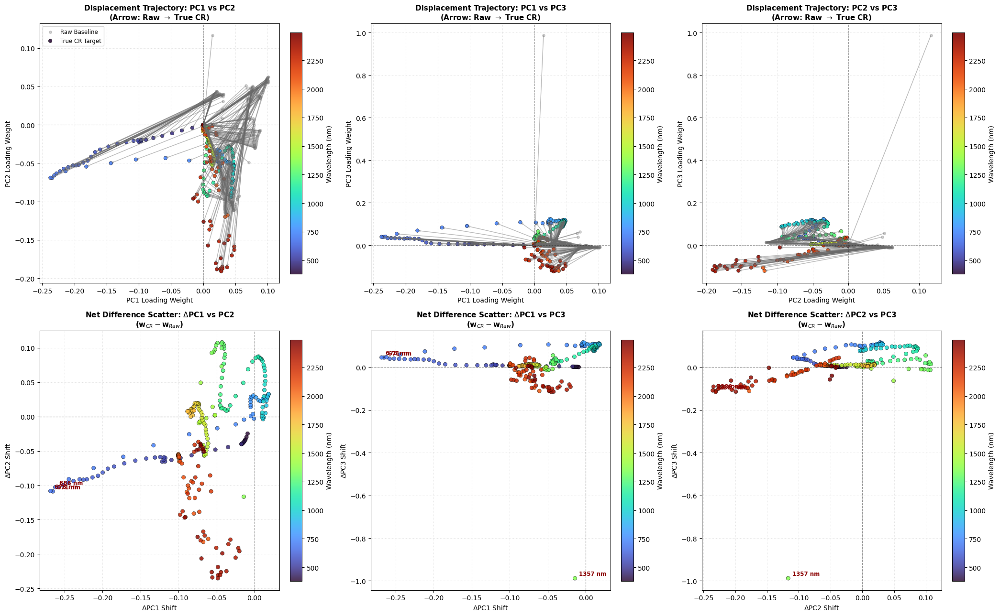


=== TOP 10 WAVELENGTHS MOST ALTERED BY CONTINUUM REMOVAL ===


,Rank,Wavelength (nm),3D Shift Magnitude (||Δw||),ΔPC1 Shift,ΔPC2 Shift,ΔPC3 Shift
0,1,1357.19,0.9949,-0.0141,-0.1166,-0.9879
1,2,678.41,0.2932,-0.2686,-0.1083,0.0454
2,3,670.95,0.2905,-0.2655,-0.1089,0.0451
3,4,685.86,0.2856,-0.2623,-0.1028,0.0467
4,5,663.49,0.2805,-0.2580,-0.1028,0.0394
5,6,656.04,0.2740,-0.2521,-0.0998,0.0398
6,7,693.32,0.2674,-0.2443,-0.0911,0.0590
7,8,648.58,0.2665,-0.2455,-0.0963,0.0386
8,9,2389.34,0.2639,-0.0482,-0.2353,-0.1091
9,10,2381.95,0.2620,-0.0453,-0.2306,-0.1157


In [66]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# 1. Sign Alignment & Delta Calculation
# -------------------------------------------------------------------------
# Extract loadings: shape (n_components, n_bands)
raw_comp = pca_raw.components_[:3].copy()
cr_comp  = pca_cr.components_[:3].copy()

# Enforce identical sign conventions between Raw and CR (positive dot product)
for k in range(3):
    if np.dot(raw_comp[k], cr_comp[k]) < 0:
        cr_comp[k] = -cr_comp[k]

# Compute net displacement vectors across all 285 bands
delta_comp = cr_comp - raw_comp  # delta_comp[k] is the shift in PC(k+1)

# Pairs to evaluate
pairs = [
    (0, 1, "PC1 vs PC2"),
    (0, 2, "PC1 vs PC3"),
    (1, 2, "PC2 vs PC3")
]

# -------------------------------------------------------------------------
# 2. Plotting the 2-Row Difference Visualizations
# -------------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(21, 13))

for col_idx, (px, py, label_pair) in enumerate(pairs):
    x_raw, y_raw = raw_comp[px], raw_comp[py]
    x_cr,  y_cr  = cr_comp[px],  cr_comp[py]
    dx, dy       = delta_comp[px], delta_comp[py]
    
    # ---------------------------------------------------------------------
    # ROW 1: Vector Displacement Map (Raw -> CR Vector Drift)
    # ---------------------------------------------------------------------
    ax1 = axes[0, col_idx]
    
    # Plot baseline raw positions (faded)
    ax1.scatter(x_raw, y_raw, c='gray', s=15, alpha=0.35, label='Raw Baseline')
    
    # Plot CR positions (colored by wavelength)
    sc1 = ax1.scatter(x_cr, y_cr, c=wl, cmap='turbo', s=30, edgecolor='black', lw=0.4, alpha=0.9, label='True CR Target')
    
    # Draw vector arrows from Raw to CR for every band
    ax1.quiver(
        x_raw, y_raw, dx, dy,
        angles='xy', scale_units='xy', scale=1,
        color='dimgray', alpha=0.45, width=0.003, headwidth=3, headlength=4
    )
    
    ax1.axhline(0, color='black', ls='--', alpha=0.35, lw=0.8)
    ax1.axvline(0, color='black', ls='--', alpha=0.35, lw=0.8)
    ax1.set_title(f"Displacement Trajectory: {label_pair}\n(Arrow: Raw $\\rightarrow$ True CR)", fontweight="bold", fontsize=11)
    ax1.set_xlabel(f"PC{px+1} Loading Weight")
    ax1.set_ylabel(f"PC{py+1} Loading Weight")
    ax1.grid(True, ls=":", alpha=0.4)
    if col_idx == 0:
        ax1.legend(loc="upper left", fontsize=8.5)
    
    cbar1 = fig.colorbar(sc1, ax=ax1, fraction=0.046, pad=0.04)
    cbar1.set_label("Wavelength (nm)", rotation=90)
    
    # ---------------------------------------------------------------------
    # ROW 2: Direct Net Delta Scatter (ΔPC_x vs ΔPC_y)
    # ---------------------------------------------------------------------
    ax2 = axes[1, col_idx]
    
    # Distance from origin = total shift magnitude in this 2D plane
    shift_magnitude = np.sqrt(dx**2 + dy**2)
    
    sc2 = ax2.scatter(
        dx, dy,
        c=wl, cmap='turbo',
        s=35, edgecolor='black', lw=0.4, alpha=0.85
    )
    
    ax2.axhline(0, color='black', ls='--', alpha=0.4, lw=0.9)
    ax2.axvline(0, color='black', ls='--', alpha=0.4, lw=0.9)
    ax2.set_title(f"Net Difference Scatter: $\\Delta${label_pair}\n($\\mathbf{{w}}_{{CR}} - \\mathbf{{w}}_{{Raw}}$)", fontweight="bold", fontsize=11)
    ax2.set_xlabel(f"$\\Delta$PC{px+1} Shift")
    ax2.set_ylabel(f"$\\Delta$PC{py+1} Shift")
    ax2.grid(True, ls=":", alpha=0.4)
    
    cbar2 = fig.colorbar(sc2, ax=ax2, fraction=0.046, pad=0.04)
    cbar2.set_label("Wavelength (nm)", rotation=90)
    
    # Annotate top 3 bands with greatest displacement in this plane
    top_shift_idx = np.argsort(shift_magnitude)[-3:]
    for t_idx in top_shift_idx:
        ax2.annotate(
            f"{wl[t_idx]:.0f} nm",
            (dx[t_idx], dy[t_idx]),
            textcoords="offset points", xytext=(6, 4),
            fontsize=8.5, fontweight="bold", color="darkred"
        )

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 3. Print Top Displaced Bands Across All 3 Subspaces
# -------------------------------------------------------------------------
total_3d_displacement = np.sqrt(delta_comp[0]**2 + delta_comp[1]**2 + delta_comp[2]**2)
top_bands = np.argsort(total_3d_displacement)[::-1][:10]

df_shift = pd.DataFrame({
    "Rank": range(1, 11),
    "Wavelength (nm)": [f"{wl[i]:.2f}" for i in top_bands],
    "3D Shift Magnitude (||Δw||)": [f"{total_3d_displacement[i]:.4f}" for i in top_bands],
    "ΔPC1 Shift": [f"{delta_comp[0, i]:.4f}" for i in top_bands],
    "ΔPC2 Shift": [f"{delta_comp[1, i]:.4f}" for i in top_bands],
    "ΔPC3 Shift": [f"{delta_comp[2, i]:.4f}" for i in top_bands]
})

print("\n=== TOP 10 WAVELENGTHS MOST ALTERED BY CONTINUUM REMOVAL ===")
display(df_shift)

Aligning sign flip for PC1 (Correlation was -0.292)


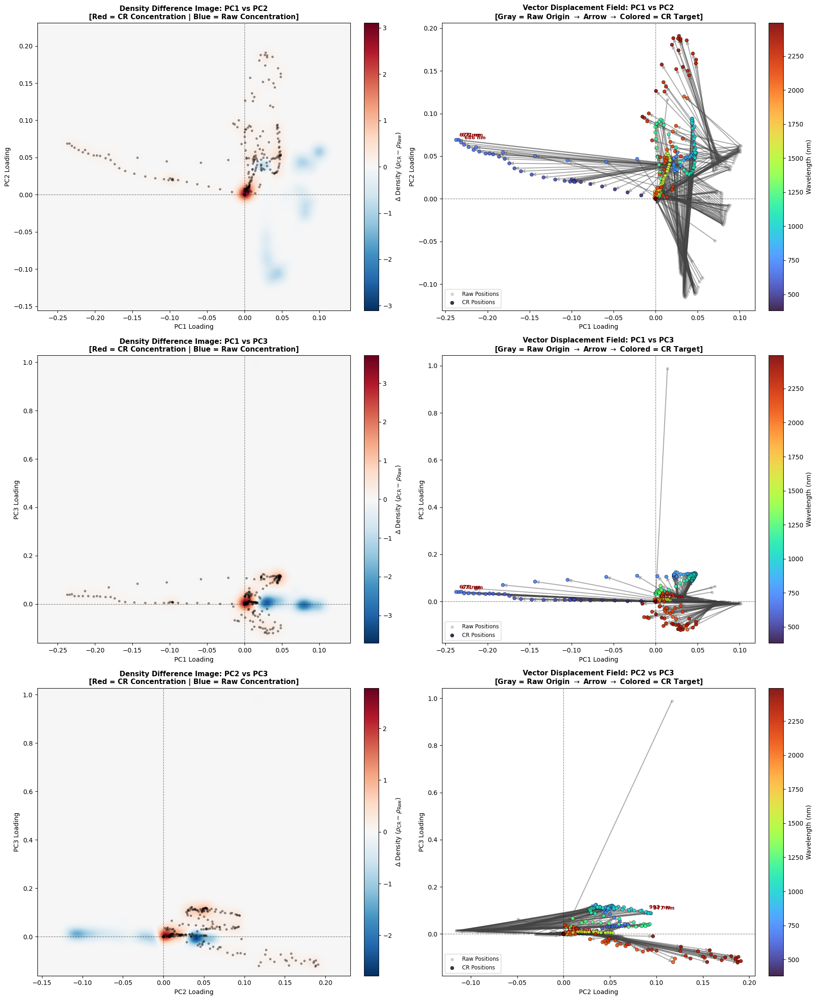


=== TOP SPECTRAL DISPLACEMENTS INDUCED BY CONTINUUM REMOVAL ===


,Component,Mean Absolute Shift,Max Shift (Delta),Max Shift Wavelength,Raw Loading,CR Loading
0,PC1,0.0669,0.2686,678.41 nm,0.0314,-0.2372
1,PC2,0.0741,0.1940,1170.80 nm,-0.1012,0.0928
2,PC3,0.0463,0.9879,1357.19 nm,0.9877,-0.0002


In [67]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# -------------------------------------------------------------------------
# 1. Sign Alignment & Loading Matrix Extraction
# -------------------------------------------------------------------------
W_raw = pca_raw.components_[:3].copy()  # Shape: (3, n_bands)
W_cr  = pca_cr.components_[:3].copy()

# Enforce positive polarity correlation to resolve PCA sign indeterminacy (+/-)
for k in range(3):
    r_corr = np.corrcoef(W_raw[k], W_cr[k])[0, 1]
    if r_corr < 0:
        print(f"Aligning sign flip for PC{k+1} (Correlation was {r_corr:.3f})")
        W_cr[k] *= -1

pc_pairs = [
    (0, 1, "PC1", "PC2"),
    (0, 2, "PC1", "PC3"),
    (1, 2, "PC2", "PC3")
]

# -------------------------------------------------------------------------
# 2. Dual Difference Plot Suite (3 PC Pairs x 2 Representations)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(3, 2, figsize=(18, 22))

grid_res = 120  # Resolution of the 2D density difference raster

for row_idx, (pc_x, pc_y, name_x, name_y) in enumerate(pc_pairs):
    x_raw, y_raw = W_raw[pc_x], W_raw[pc_y]
    x_cr,  y_cr  = W_cr[pc_x],  W_cr[pc_y]
    
    # Establish shared bounding box for the pair
    pad = 0.04
    x_min = min(np.min(x_raw), np.min(x_cr)) - pad
    x_max = max(np.max(x_raw), np.max(x_cr)) + pad
    y_min = min(np.min(y_raw), np.min(y_cr)) - pad
    y_max = max(np.max(y_raw), np.max(y_cr)) + pad
    
    # ---------------------------------------------------------------------
    # COLUMN 1: 2D Binned Density Difference Image (Delta = CR - Raw)
    # ---------------------------------------------------------------------
    ax_img = axes[row_idx, 0]
    
    # 2D Binned Histogram
    x_edges = np.linspace(x_min, x_max, grid_res + 1)
    y_edges = np.linspace(y_min, y_max, grid_res + 1)
    
    H_raw, _, _ = np.histogram2d(x_raw, y_raw, bins=[x_edges, y_edges])
    H_cr,  _, _ = np.histogram2d(x_cr,  y_cr,  bins=[x_edges, y_edges])
    
    # Gaussian continuous smoothing
    sigma_blur = 1.8
    D_raw = gaussian_filter(H_raw.T, sigma=sigma_blur)
    D_cr  = gaussian_filter(H_cr.T,  sigma=sigma_blur)
    
    # Difference Image: Delta > 0 (CR gain), Delta < 0 (Raw loss)
    diff_density = D_cr - D_raw
    abs_limit = np.nanmax(np.abs(diff_density))
    
    im = ax_img.imshow(
        diff_density, 
        extent=[x_min, x_max, y_min, y_max], 
        origin='lower', 
        cmap='RdBu_r', 
        vmin=-abs_limit, 
        vmax=abs_limit,
        aspect='auto',
        interpolation='bicubic'
    )
    
    # Reference baselines and CR point overlays
    ax_img.axhline(0, color='black', ls='--', lw=0.8, alpha=0.5)
    ax_img.axvline(0, color='black', ls='--', lw=0.8, alpha=0.5)
    ax_img.scatter(x_cr, y_cr, c='black', s=8, alpha=0.35, label='CR Band Positions')
    
    ax_img.set_title(f"Density Difference Image: {name_x} vs {name_y}\n[Red = CR Concentration | Blue = Raw Concentration]", 
                     fontweight='bold', fontsize=11)
    ax_img.set_xlabel(f"{name_x} Loading")
    ax_img.set_ylabel(f"{name_y} Loading")
    
    cbar1 = fig.colorbar(im, ax=ax_img, fraction=0.046, pad=0.04)
    cbar1.set_label(r"$\Delta$ Density ($\rho_{\mathrm{CR}} - \rho_{\mathrm{Raw}}$)", rotation=90)

    # ---------------------------------------------------------------------
    # COLUMN 2: Vector Displacement / Trajectory Field (Raw -> CR)
    # ---------------------------------------------------------------------
    ax_vec = axes[row_idx, 1]
    
    # Displacement vectors
    dx = x_cr - x_raw
    dy = y_cr - y_raw
    displacement_mag = np.sqrt(dx**2 + dy**2)
    
    # Plot start points (Raw = gray)
    ax_vec.scatter(x_raw, y_raw, c='#aaaaaa', s=16, alpha=0.5, label='Raw Positions')
    
    # Draw vector arrows from Raw to CR
    ax_vec.quiver(
        x_raw, y_raw, dx, dy, 
        angles='xy', scale_units='xy', scale=1, 
        color='#444444', width=0.003, headwidth=4, headlength=5, alpha=0.45
    )
    
    # Plot destination points (CR = colored by wavelength)
    sc = ax_vec.scatter(
        x_cr, y_cr, 
        c=wl, cmap='turbo', s=30, edgecolor='black', lw=0.4, alpha=0.9,
        label='CR Positions'
    )
    
    ax_vec.axhline(0, color='black', ls='--', lw=0.8, alpha=0.5)
    ax_vec.axvline(0, color='black', ls='--', lw=0.8, alpha=0.5)
    
    ax_vec.set_title(f"Vector Displacement Field: {name_x} vs {name_y}\n[Gray = Raw Origin $\\rightarrow$ Arrow $\\rightarrow$ Colored = CR Target]", 
                     fontweight='bold', fontsize=11)
    ax_vec.set_xlabel(f"{name_x} Loading")
    ax_vec.set_ylabel(f"{name_y} Loading")
    ax_vec.legend(loc='lower left', fontsize=8.5)
    
    cbar2 = fig.colorbar(sc, ax=ax_vec, fraction=0.046, pad=0.04)
    cbar2.set_label("Wavelength (nm)", rotation=90)
    
    # Annotate top 3 maximum migration bands
    top3_idx = np.argsort(displacement_mag)[-3:]
    for idx in top3_idx:
        ax_vec.annotate(
            f"{wl[idx]:.0f} nm", 
            (x_cr[idx], y_cr[idx]),
            textcoords="offset points", xytext=(5, 5), 
            fontsize=8, fontweight='bold', color='darkred'
        )

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 3. Quantitative Displacement Summary Table
# -------------------------------------------------------------------------
df_shifts = []
for pc_idx, pc_name in enumerate(["PC1", "PC2", "PC3"]):
    delta_w = np.abs(W_cr[pc_idx] - W_raw[pc_idx])
    max_band_idx = np.argmax(delta_w)
    df_shifts.append({
        "Component": pc_name,
        "Mean Absolute Shift": f"{np.mean(delta_w):.4f}",
        "Max Shift (Delta)": f"{delta_w[max_band_idx]:.4f}",
        "Max Shift Wavelength": f"{wl[max_band_idx]:.2f} nm",
        "Raw Loading": f"{W_raw[pc_idx, max_band_idx]:.4f}",
        "CR Loading": f"{W_cr[pc_idx, max_band_idx]:.4f}"
    })

print("\n=== TOP SPECTRAL DISPLACEMENTS INDUCED BY CONTINUUM REMOVAL ===")
display(pd.DataFrame(df_shifts))

### Compare raw and continuum-removed clustering and reference matches

This cell fixes the comparison at `k_val = 3`, fits separate K-Means models to the raw t-SNE embedding (`T_raw`) and continuum-removed embedding (`T_cr`), and attributes each set of cluster mean spectra using the USGS reference workflow. It produces side-by-side t-SNE partitions, spatial class maps, mean reflectance curves, and continuum-removed absorption profiles. A final table compares the class designations, top USGS matches, SAM angles, and the number of pixels whose numeric labels differ between the two maps.

**Interpretation caution:** cluster IDs from two independent K-Means fits are nominal and can be permuted. Therefore, the reported pixel-drift count is only directly meaningful when corresponding class labels are aligned between the two fits; a label permutation can inflate apparent disagreement even if the underlying partitions are similar. Treat USGS matches and labels as candidate interpretations requiring geological validation.

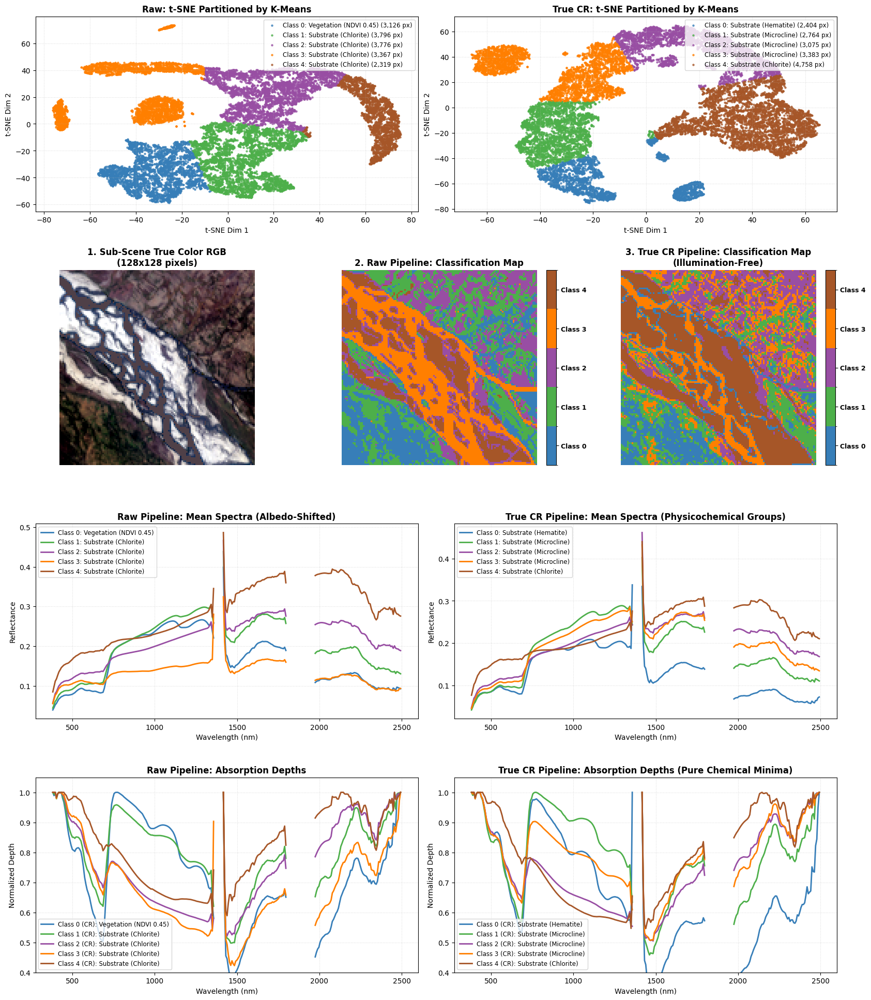


================ SIDE-BY-SIDE PIPELINE ATTRIBUTION REPORT ================


,Cluster ID,Color Code,Raw Pipeline Designation,Raw USGS Match,Raw SAM (deg),CR Pipeline Designation,CR USGS Match,CR SAM (deg),Matched Pixel Overlap,Pixel Drift Count
0,0,#377EB8,Vegetation (NDVI 0.45),Oak Oak-Leaf-2 dried ASDFRa,7.96°,Substrate (Hematite),Hematite HS45.3 ASDFRb AREF,3.95°,1472,2586
1,1,#4DAF4A,Substrate (Chlorite),Chlorite HS179.2B ASDFRb ARE,2.51°,Substrate (Microcline),Microcline HS151.6 Feldspar,3.47°,1444,3672
2,2,#984EA3,Substrate (Chlorite),Chlorite HS179.2B ASDFRb ARE,1.51°,Substrate (Microcline),Microcline HS151.6 Feldspar,1.88°,2217,2417
3,3,#FF7F00,Substrate (Chlorite),Chlorite HS179.2B ASDFRb ARE,2.04°,Substrate (Microcline),Microcline HS151.6 Feldspar,2.81°,1236,4278
4,4,#A65628,Substrate (Chlorite),Chlorite HS179.2B ASDFRb ARE,1.51°,Substrate (Chlorite),Chlorite HS179.1B ASDFRb ARE,1.54°,2259,2559


In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap, BoundaryNorm
from sklearn.cluster import KMeans
from scipy.optimize import linear_sum_assignment

# -------------------------------------------------------------------------
# 0. Display & Spectral Helper Functions
# -------------------------------------------------------------------------
def stretch_rgb_local(rgb_data, p_low=2, p_high=98):
    stretched = np.zeros_like(rgb_data, dtype=np.float32)
    for b in range(3):
        bd = rgb_data[:, :, b]
        valid = np.isfinite(bd) & (bd > 0)
        if np.sum(valid) > 0:
            vmin = np.percentile(bd[valid], p_low)
            vmax = np.percentile(bd[valid], p_high)
            stretched[:, :, b] = np.clip((bd - vmin) / max(vmax - vmin, 1e-5), 0, 1)
    return stretched

def safe_plot_spec(ax, wavelengths, spectrum, **kwargs):
    if 'plot_spectrum_gap_aware' in globals():
        plot_spectrum_gap_aware(ax, wavelengths, spectrum, **kwargs)
    else:
        w = np.asarray(wavelengths)
        s = np.asarray(spectrum)
        gap_mask = ((w >= 1340) & (w <= 1450)) | ((w >= 1790) & (w <= 1970))
        s_masked = np.ma.masked_where(gap_mask | ~np.isfinite(s) | (s <= 0), s)
        ax.plot(w, s_masked, **kwargs)

# -------------------------------------------------------------------------
# 1. Configuration & Label Extraction (k = 3)
# -------------------------------------------------------------------------
k_val = 5
DISTINCT_COLORS = ['#377EB8',  # Blue
    '#4DAF4A',  # Green
    '#984EA3',  # Purple
    '#FF7F00',  # Orange
    '#A65628' ]
palette = DISTINCT_COLORS[:k_val]
custom_cmap = ListedColormap(palette)
bounds = np.arange(k_val + 1) - 0.5
norm = BoundaryNorm(bounds, custom_cmap.N)

actual_crop_size = crop_size if 'crop_size' in globals() else int(np.sqrt(len(X)))

# -------------------------------------------------------------------------
# 2. Fit K-Means on Both Manifolds & Align Cluster Colors
# -------------------------------------------------------------------------
km_raw = KMeans(n_clusters=k_val, n_init=10, random_state=0)
labels_raw = km_raw.fit_predict(T_raw)

km_cr = KMeans(n_clusters=k_val, n_init=10, random_state=0)
labels_cr_initial = km_cr.fit_predict(T_cr)

# Deterministically order labels_raw by descending NDVI
b_red = np.argmin(np.abs(wl - 660))
b_nir = np.argmin(np.abs(wl - 860))

ndvis_raw = [
    (np.nanmean(X[labels_raw == c, b_nir]) - np.nanmean(X[labels_raw == c, b_red])) /
    (np.nanmean(X[labels_raw == c, b_nir]) + np.nanmean(X[labels_raw == c, b_red]) + 1e-6)
    for c in range(k_val)
]
order_raw = np.argsort(ndvis_raw)[::-1]
raw_map_dict = {old_c: new_c for new_c, old_c in enumerate(order_raw)}
labels_raw = np.array([raw_map_dict[c] for c in labels_raw])

# Align labels_cr to labels_raw via Hungarian matching on mutual spatial overlap
contingency = np.zeros((k_val, k_val), dtype=int)
for r in range(k_val):
    for c in range(k_val):
        contingency[r, c] = np.sum((labels_raw == r) & (labels_cr_initial == c))

row_ind, col_ind = linear_sum_assignment(-contingency)
cr_to_raw_map = {col_ind[i]: row_ind[i] for i in range(k_val)}
labels_cr = np.array([cr_to_raw_map[c] for c in labels_cr_initial])

# -------------------------------------------------------------------------
# 3. Spectral Angle Mapper (SAM) Matching Against USGS Reference Library
# -------------------------------------------------------------------------
swir_diagnostic = (wl >= 2100) & (wl <= 2380)

def identify_clusters(X_data, cluster_labels, use_cr_matching=False):
    ident_dict = {}
    for c in range(k_val):
        c_pixels = X_data[cluster_labels == c]
        mean_spec = np.nanmean(c_pixels, axis=0)
        cr_mean = continuum_removal(wl, mean_spec)
        ndvi = (mean_spec[b_nir] - mean_spec[b_red]) / (mean_spec[b_nir] + mean_spec[b_red] + 1e-6)
        
        if ndvi >= 0.40 and 'usgs_vegetation' in globals() and len(usgs_vegetation) > 0:
            scores = {name: spectral_angle_mapper(mean_spec, ref) for name, ref in usgs_vegetation.items()}
            sorted_m = sorted(scores.items(), key=lambda x: x[1])
            top_name, top_ang = sorted_m[0]
            sci_label = f"Vegetation (NDVI {ndvi:.2f})"
            ref_spec = usgs_vegetation[top_name]
        elif 'usgs_minerals' in globals() and len(usgs_minerals) > 0:
            scores = {}
            for name, ref in usgs_minerals.items():
                ref_cr = continuum_removal(wl, ref)
                if use_cr_matching:
                    ang = spectral_angle_mapper(cr_mean[swir_diagnostic], ref_cr[swir_diagnostic])
                else:
                    ang = spectral_angle_mapper(mean_spec[swir_diagnostic], ref[swir_diagnostic])
                scores[name] = ang
            sorted_m = sorted(scores.items(), key=lambda x: x[1])
            top_name, top_ang = sorted_m[0]
            clean_min = top_name.split()[0]
            sci_label = f"Substrate ({clean_min})"
            ref_spec = usgs_minerals[top_name]
        else:
            top_name, top_ang = "USGS Reference Standard", 0.0
            sci_label = f"Class {c}"
            ref_spec = mean_spec
            sorted_m = [(top_name, top_ang)]
            
        ident_dict[c] = {
            "mean_spec": mean_spec,
            "cr_spec": cr_mean,
            "ndvi": ndvi,
            "top_match": top_name,
            "angle_deg": np.degrees(top_ang),
            "label": sci_label,
            "ref_spec": ref_spec,
            "top5": sorted_m[:5]
        }
    return ident_dict

results_raw = identify_clusters(X, labels_raw, use_cr_matching=False)
results_cr  = identify_clusters(X, labels_cr, use_cr_matching=True)

# -------------------------------------------------------------------------
# 4. Prepare Sub-Scene True Color RGB
# -------------------------------------------------------------------------
b_r = np.argmin(np.abs(wl - 650))
b_g = np.argmin(np.abs(wl - 560))
b_b = np.argmin(np.abs(wl - 470))

if 'crop' in globals() and crop.shape[:2] == (actual_crop_size, actual_crop_size):
    true_color_sub = stretch_rgb_local(crop[:, :, [b_r, b_g, b_b]])
elif 'cube' in globals() and 'r_start' in globals() and 'c_start' in globals():
    true_color_sub = stretch_rgb_local(cube[r_start:r_start + actual_crop_size, c_start:c_start + actual_crop_size, [b_r, b_g, b_b]])
else:
    true_color_sub = stretch_rgb_local(X[:, [b_r, b_g, b_b]].reshape(actual_crop_size, actual_crop_size, 3))

# -------------------------------------------------------------------------
# 5. Dual-Pipeline Diagnostic Visualizations (Synchronized Colors & RGB Crop)
# -------------------------------------------------------------------------
fig = plt.figure(figsize=(20, 24))
gs = gridspec.GridSpec(4, 6, figure=fig, hspace=0.30, wspace=0.35)

# --- ROW 1: Partitioned t-SNE Manifold (2 Columns) ---
ax_tsne_raw = fig.add_subplot(gs[0, 0:3])
ax_tsne_cr  = fig.add_subplot(gs[0, 3:6])

for c in range(k_val):
    m_raw = (labels_raw == c)
    ax_tsne_raw.scatter(T_raw[m_raw, 0], T_raw[m_raw, 1], color=palette[c], s=5, alpha=0.7,
                        label=f"Class {c}: {results_raw[c]['label']} ({np.sum(m_raw):,} px)")
    m_cr = (labels_cr == c)
    ax_tsne_cr.scatter(T_cr[m_cr, 0], T_cr[m_cr, 1], color=palette[c], s=5, alpha=0.7,
                       label=f"Class {c}: {results_cr[c]['label']} ({np.sum(m_cr):,} px)")

ax_tsne_raw.set_title("Raw: t-SNE Partitioned by K-Means", fontweight="bold", fontsize=12)
ax_tsne_raw.set_xlabel("t-SNE Dim 1"); ax_tsne_raw.set_ylabel("t-SNE Dim 2")
ax_tsne_raw.legend(loc="upper right", fontsize=8.5); ax_tsne_raw.grid(True, linestyle=":", alpha=0.45)

ax_tsne_cr.set_title("True CR: t-SNE Partitioned by K-Means", fontweight="bold", fontsize=12)
ax_tsne_cr.set_xlabel("t-SNE Dim 1"); ax_tsne_cr.set_ylabel("t-SNE Dim 2")
ax_tsne_cr.legend(loc="upper right", fontsize=8.5); ax_tsne_cr.grid(True, linestyle=":", alpha=0.45)

# --- ROW 2: Spatial Classification Maps + True Color Sub-Scene (3 Columns) ---
ax_rgb = fig.add_subplot(gs[1, 0:2])
ax_map_raw = fig.add_subplot(gs[1, 2:4])
ax_map_cr  = fig.add_subplot(gs[1, 4:6])

map_raw = labels_raw.reshape(actual_crop_size, actual_crop_size)
map_cr  = labels_cr.reshape(actual_crop_size, actual_crop_size)

# 1. Sub-Scene True Color
ax_rgb.imshow(true_color_sub)
ax_rgb.set_title(f"1. Sub-Scene True Color RGB\n({actual_crop_size}x{actual_crop_size} pixels)", fontweight="bold", fontsize=12)
ax_rgb.axis("off")

# 2. Raw Classification Map
im_raw = ax_map_raw.imshow(map_raw, cmap=custom_cmap, norm=norm, interpolation="nearest")
ax_map_raw.set_title("2. Raw Pipeline: Classification Map", fontweight="bold", fontsize=12)
ax_map_raw.axis("off")
cb_raw = fig.colorbar(im_raw, ax=ax_map_raw, fraction=0.046, pad=0.04, ticks=range(k_val))
cb_raw.set_ticklabels([f"Class {c}" for c in range(k_val)], fontsize=9, fontweight="bold")

# 3. True CR Classification Map
im_cr = ax_map_cr.imshow(map_cr, cmap=custom_cmap, norm=norm, interpolation="nearest")
ax_map_cr.set_title("3. True CR Pipeline: Classification Map\n(Illumination-Free)", fontweight="bold", fontsize=12)
ax_map_cr.axis("off")
cb_cr = fig.colorbar(im_cr, ax=ax_map_cr, fraction=0.046, pad=0.04, ticks=range(k_val))
cb_cr.set_ticklabels([f"Class {c}" for c in range(k_val)], fontsize=9, fontweight="bold")

# --- ROW 3: Mean Reflectance Spectra per Cluster (2 Columns) ---
ax_spec_raw = fig.add_subplot(gs[2, 0:3])
ax_spec_cr  = fig.add_subplot(gs[2, 3:6])

for c in range(k_val):
    safe_plot_spec(ax_spec_raw, wl, results_raw[c]["mean_spec"], color=palette[c], lw=2.0,
                   label=f"Class {c}: {results_raw[c]['label']}")
    safe_plot_spec(ax_spec_cr, wl, results_cr[c]["mean_spec"], color=palette[c], lw=2.0,
                   label=f"Class {c}: {results_cr[c]['label']}")

ax_spec_raw.set_title("Raw Pipeline: Mean Spectra (Albedo-Shifted)", fontweight="bold", fontsize=12)
ax_spec_raw.set_xlabel("Wavelength (nm)"); ax_spec_raw.set_ylabel("Reflectance")
ax_spec_raw.grid(True, linestyle=":", alpha=0.45); ax_spec_raw.legend(loc="upper left", fontsize=8.5)

ax_spec_cr.set_title("True CR Pipeline: Mean Spectra (Physicochemical Groups)", fontweight="bold", fontsize=12)
ax_spec_cr.set_xlabel("Wavelength (nm)"); ax_spec_cr.set_ylabel("Reflectance")
ax_spec_cr.grid(True, linestyle=":", alpha=0.45); ax_spec_cr.legend(loc="upper left", fontsize=8.5)

# --- ROW 4: Continuum-Removed Absorption Profiles (2 Columns) ---
ax_abs_raw = fig.add_subplot(gs[3, 0:3])
ax_abs_cr  = fig.add_subplot(gs[3, 3:6])

for c in range(k_val):
    safe_plot_spec(ax_abs_raw, wl, results_raw[c]["cr_spec"], color=palette[c], lw=2.0,
                   label=f"Class {c} (CR): {results_raw[c]['label']}")
    safe_plot_spec(ax_abs_cr, wl, results_cr[c]["cr_spec"], color=palette[c], lw=2.0,
                   label=f"Class {c} (CR): {results_cr[c]['label']}")

ax_abs_raw.set_title("Raw Pipeline: Absorption Depths", fontweight="bold", fontsize=12)
ax_abs_raw.set_xlabel("Wavelength (nm)"); ax_abs_raw.set_ylabel("Normalized Depth")
ax_abs_raw.set_ylim(0.4, 1.05); ax_abs_raw.grid(True, linestyle=":", alpha=0.45)
ax_abs_raw.legend(loc="lower left", fontsize=8.5)

ax_abs_cr.set_title("True CR Pipeline: Absorption Depths (Pure Chemical Minima)", fontweight="bold", fontsize=12)
ax_abs_cr.set_xlabel("Wavelength (nm)"); ax_abs_cr.set_ylabel("Normalized Depth")
ax_abs_cr.set_ylim(0.4, 1.05); ax_abs_cr.grid(True, linestyle=":", alpha=0.45)
ax_abs_cr.legend(loc="lower left", fontsize=8.5)

plt.show()

# -------------------------------------------------------------------------
# 6. Comparative Scientific Attribution Report
# -------------------------------------------------------------------------
df_compare = pd.DataFrame([
    {
        "Cluster ID": c,
        "Color Code": palette[c],
        "Raw Pipeline Designation": results_raw[c]["label"],
        "Raw USGS Match": results_raw[c]["top_match"][:28],
        "Raw SAM (deg)": f"{results_raw[c]['angle_deg']:.2f}°",
        "CR Pipeline Designation": results_cr[c]["label"],
        "CR USGS Match": results_cr[c]["top_match"][:28],
        "CR SAM (deg)": f"{results_cr[c]['angle_deg']:.2f}°",
        "Matched Pixel Overlap": int(np.sum((labels_raw == c) & (labels_cr == c))),
        "Pixel Drift Count": int(np.sum((labels_raw == c) != (labels_cr == c)))
    }
    for c in range(k_val)
])

print("\n================ SIDE-BY-SIDE PIPELINE ATTRIBUTION REPORT ================")
display(df_compare)

### Apply continuum-removed classification to the complete EMIT scene

This cell performs the continuum-removed full-scene projection. It resolves the image cube and quality mask, trains a `NearestCentroid` classifier from the crop's continuum-removed PCA scores and cluster labels, and defines a batched upper-hull continuum-removal routine for the same three wavelength windows used in the comparison workflow. Valid full-scene pixels are processed in batches: raw spectra are continuum-removed, transformed by the fitted `pca_cr` model, and assigned to the nearest crop-trained class centroid.

The outputs are a full-scene continuum-removed classification map beside the true-colour image, plus a scene-wide table containing class designation, USGS reference match, diagnostic SAM angle, pixel count, and scene-cover percentage.

**Important consistency check:** the crop labels, `P_cr`, `pca_cr`, wavelength array, and full-scene continuum-removal procedure must all refer to the same preprocessing and class definition. The final map extrapolates crop-derived classes to the full scene; it is not independent ground-truth validation, and the reported reference match should be treated as a candidate attribution.

Total Scene Dimensions : 1280 x 1242 (1,589,760 pixels)
Valid Surface Pixels   : 1,021,607 (64.26% land cover)
Training Nearest-Centroid classifier on 16,384 crop samples across 4 CR-PCs...
Projecting 1,021,607 pixels in 26 batches (batch size = 40,000)...
  -> Processed batch  5/26 ( 19.6%)
  -> Processed batch 10/26 ( 39.2%)
  -> Processed batch 15/26 ( 58.7%)
  -> Processed batch 20/26 ( 78.3%)
  -> Processed batch 25/26 ( 97.9%)
  -> Processed batch 26/26 (100.0%)


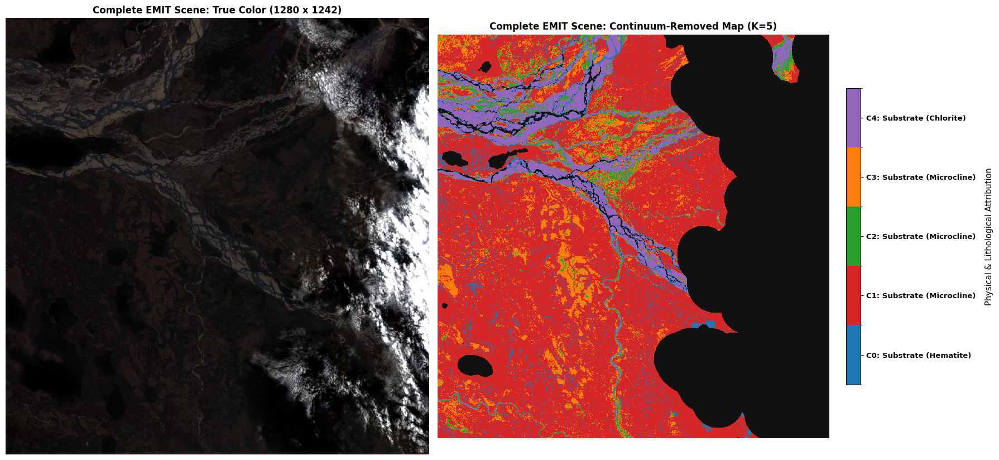

================ FULL SCENE SURFACE COMPOSITION REPORT ================


,Cluster ID,Class Designation,USGS Library Reference,Diagnostic SAM,Pixel Count,Scene Cover (%)
0,0,C0: Substrate (Hematite),Hematite HS45.3 ASDFRb AREF,3.95°,"58,975",5.77%
1,1,C1: Substrate (Microcline),Microcline HS151.6 Feldspar ASDFRc AREF,3.47°,"701,349",68.65%
2,2,C2: Substrate (Microcline),Microcline HS151.6 Feldspar ASDFRc AREF,1.88°,"48,538",4.75%
3,3,C3: Substrate (Microcline),Microcline HS151.6 Feldspar ASDFRc AREF,2.81°,"110,695",10.84%
4,4,C4: Substrate (Chlorite),Chlorite HS179.1B ASDFRb AREF,1.54°,"102,050",9.99%


In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from scipy.spatial import ConvexHull
from sklearn.neighbors import NearestCentroid

# -------------------------------------------------------------------------
# 1. Resolve Scene Tensor, Quality Mask, and Models
# -------------------------------------------------------------------------
full_scene = img if 'img' in globals() else cube
rows, cols, bands = full_scene.shape
n_bands = bands if 'n_bands' not in globals() else n_bands
full_flat = full_scene.reshape(-1, n_bands)

# Resolve valid quality mask
if 'valid_pixel_mask' in globals() and valid_pixel_mask.shape == (rows, cols):
    valid_mask = valid_pixel_mask
elif 'flag' in globals() and flag.shape == (rows, cols):
    valid_mask = (flag == 0)
else:
    valid_mask = np.all(full_scene > 0, axis=-1)

valid_indices = np.flatnonzero(valid_mask.ravel())
print(f"Total Scene Dimensions : {rows} x {cols} ({rows * cols:,} pixels)")
print(f"Valid Surface Pixels   : {len(valid_indices):,} ({(len(valid_indices)/(rows*cols))*100:.2f}% land cover)")

# Resolve PCA dimension and cluster labels from the Continuum-Removed pipeline
n_pcs = n_pcs_used if 'n_pcs_used' in globals() else (elbow if 'elbow' in globals() else 4)
active_labels = labels_cr if 'labels_cr' in globals() else labels
k_val = len(np.unique(active_labels))

# Train Nearest-Centroid classifier in the CR-PCA latent space
print(f"Training Nearest-Centroid classifier on {len(active_labels):,} crop samples across {n_pcs} CR-PCs...")
clf_cr = NearestCentroid()
clf_cr.fit(P_cr[:, :n_pcs], active_labels)

# -------------------------------------------------------------------------
# 2. Optimized Batched Continuum Removal Helper
# -------------------------------------------------------------------------
# Define the 3 primary atmospheric transmission windows
win_masks = [
    (wl >= 450) & (wl <= 1320),   # VNIR: Chlorophyll & Fe-oxides
    (wl >= 1480) & (wl <= 1780),  # SWIR-1: Albedo & Structural Cellulose
    (wl >= 2050) & (wl <= 2450)   # SWIR-2: Diagnostic Phyllosilicates & Carbonates
]
win_indices = [np.where(m)[0] for m in win_masks]
win_wls = [wl[m] for m in win_masks]

def batch_upper_hull_cr(batch_spectra):
    """
    Computes upper convex hull continuum removal for a batch of spectra.
    Guarantees X_cr <= 1.0 without illumination/albedo artifacts.
    """
    X_cr_batch = np.ones_like(batch_spectra, dtype=np.float32)
    n_samples = len(batch_spectra)
    
    for w_idx, sub_wl in zip(win_indices, win_wls):
        sub_X = batch_spectra[:, w_idx]
        n_pts = len(sub_wl)
        
        # Process upper convex hull per spectrum in batch
        cont_matrix = np.empty_like(sub_X)
        for i in range(n_samples):
            s = sub_X[i]
            if np.all(s <= 0):
                cont_matrix[i] = np.maximum(s, 1e-4)
                continue
            try:
                pts = np.vstack([sub_wl, s]).T
                poly = np.vstack([pts, [[sub_wl[-1], 0.0], [sub_wl[0], 0.0]]])
                hull = ConvexHull(poly)
                upper_v = sorted([v for v in hull.vertices if v < n_pts])
                if 0 not in upper_v:
                    upper_v.insert(0, 0)
                if (n_pts - 1) not in upper_v:
                    upper_v.append(n_pts - 1)
                continuum = np.interp(sub_wl, sub_wl[upper_v], s[upper_v])
                cont_matrix[i] = np.maximum(continuum, 1e-4)
            except Exception:
                p = np.polyfit([sub_wl[0], sub_wl[-1]], [s[0], s[-1]], 1)
                cont_matrix[i] = np.maximum(np.polyval(p, sub_wl), 1e-4)
                
        X_cr_batch[:, w_idx] = np.clip(sub_X / cont_matrix, 0.0, 1.0)
        
    return X_cr_batch

# -------------------------------------------------------------------------
# 3. Batched Full-Scene Projection (X -> X_cr -> PCA_cr -> NearestCentroid)
# -------------------------------------------------------------------------
full_scene_labels = np.full(rows * cols, -1, dtype=np.int8)
batch_sz = 40000
n_batches = int(np.ceil(len(valid_indices) / batch_sz))

print(f"Projecting {len(valid_indices):,} pixels in {n_batches} batches (batch size = {batch_sz:,})...")

for b in range(n_batches):
    b_start = b * batch_sz
    b_end = min(b_start + batch_sz, len(valid_indices))
    b_idx = valid_indices[b_start:b_end]
    
    # 1. Slice raw reflectances
    X_raw_b = full_flat[b_idx]
    
    # 2. Segmented upper convex hull continuum removal
    X_cr_b = batch_upper_hull_cr(X_raw_b)
    
    # 3. Project into CR-PCA subspace
    P_cr_b = pca_cr.transform(X_cr_b)[:, :n_pcs]
    
    # 4. Predict nearest spectral class
    full_scene_labels[b_idx] = clf_cr.predict(P_cr_b).astype(np.int8)
    
    if (b + 1) % 5 == 0 or (b + 1) == n_batches:
        print(f"  -> Processed batch {b + 1:2d}/{n_batches} ({(b_end / len(valid_indices))*100:5.1f}%)")

# Reshape into full 2D spatial map and mask non-surface pixels
full_map = full_scene_labels.reshape(rows, cols)
masked_full_map = np.ma.masked_where(full_map < 0, full_map)

# -------------------------------------------------------------------------
# 4. Side-by-Side Visualization (True Color vs CR Classification Map)
# -------------------------------------------------------------------------
DISTINCT_COLORS = ['#1f77b4', '#d62728', '#2ca02c', '#ff7f0e', '#9467bd', '#17becf']
palette = DISTINCT_COLORS[:k_val]
custom_cmap = ListedColormap(palette)
custom_cmap.set_bad(color='#111111')  # Unclassified/masked pixels in dark charcoal
bounds = np.arange(k_val + 1) - 0.5
norm = BoundaryNorm(bounds, custom_cmap.N)

# Prepare True Color RGB composite
b_func = band_idx if 'band_idx' in globals() else band
disp_fn = stretch_rgb if 'stretch_rgb' in globals() else stretch
r_b, g_b, b_b = b_func(650), b_func(560), b_func(470)
true_color_full = disp_fn(full_scene[:, :, [r_b, g_b, b_b]])

# Class labels resolved from Cell 14 attribution
class_names = []
for c in range(k_val):
    if 'results_cr' in globals() and c in results_cr:
        class_names.append(f"C{c}: {results_cr[c]['label']}")
    else:
        class_names.append(f"Class {c}")

fig, axes = plt.subplots(1, 2, figsize=(18, 9))

# Subplot 1: True Color Full Scene
axes[0].imshow(true_color_full)
axes[0].set_title(f"Complete EMIT Scene: True Color ({rows} x {cols})", fontweight="bold", fontsize=12)
axes[0].axis("off")

# Subplot 2: Continuum-Removed Physical Classification Map
im_map = axes[1].imshow(masked_full_map, cmap=custom_cmap, norm=norm, interpolation="nearest")
axes[1].set_title(f"Complete EMIT Scene: Continuum-Removed Map (K={k_val})", fontweight="bold", fontsize=12)
axes[1].axis("off")

# Synchronized discrete colorbar
cbar = fig.colorbar(im_map, ax=axes[1], fraction=0.035, pad=0.04, ticks=range(k_val))
cbar.set_ticklabels(class_names, fontsize=9.5, fontweight="bold")
cbar.ax.set_ylabel("Physical & Lithological Attribution", rotation=90, labelpad=12, fontsize=10.5)

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 5. Scene-Wide Surface Distribution Statistics
# -------------------------------------------------------------------------
print("================ FULL SCENE SURFACE COMPOSITION REPORT ================")
df_scene_stats = []
for c in range(k_val):
    c_count = int(np.sum(full_scene_labels == c))
    c_pct = (c_count / len(valid_indices)) * 100
    ref_match = results_cr[c]["top_match"] if ('results_cr' in globals() and c in results_cr) else "N/A"
    sam_angle = f"{results_cr[c]['angle_deg']:.2f}°" if ('results_cr' in globals() and c in results_cr) else "N/A"
    
    df_scene_stats.append({
        "Cluster ID": c,
        "Class Designation": class_names[c],
        "USGS Library Reference": ref_match,
        "Diagnostic SAM": sam_angle,
        "Pixel Count": f"{c_count:,}",
        "Scene Cover (%)": f"{c_pct:.2f}%"
    })

display(pd.DataFrame(df_scene_stats))